# Лабораторна робота №1

## Комплексний дослідницький аналіз даних, просунута попередня обробка та аугментація даних для моделей машинного навчання

**Дисципліна:** Методологія та процеси моделювання у штучному інтелекті

**Виконав:** Колодійчук Олександр, ст. гр. КНСШ-13

---

**Датасет:** Rain in Australia (weatherAUS), [Kaggle](https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package)
Первинне джерело – Australian Bureau of Meteorology.

**Задача:** бінарна класифікація – прогноз опадів на наступну добу (`RainTomorrow`).

### Структура ноутбука

| Розділ | Зміст | Пункт методички |
|---|---|---|
| **0** | Підготовка середовища | – |
| **1** | Вибір та обґрунтування датасету | 1 |
| **2** | Глибинний дослідницький аналіз (Advanced EDA) | 2 |
| **3** | Комплексна обробка та трансформація даних | 3 |
| **4** | Аугментація та генерування даних | 4 |
| **5** | Збереження артефактів | 5 |

---
# Розділ 0. Підготовка середовища

### Комірка 0.1 – встановлення відсутніх бібліотек

Перевіряємо наявність `imbalanced-learn` (реалізації SMOTE, SMOTE-NC, ADASYN) і
встановлюємо лише за потреби. Решта бібліотек присутні в стандартному образі Google Colab.

In [1]:
# --- Перевірка та встановлення залежностей ---
# Встановлюємо пакет тільки якщо його немає: це економить час при повторних запусках.
import importlib.util
import subprocess
import sys

for pkg, module in [("imbalanced-learn", "imblearn")]:
    if importlib.util.find_spec(module) is None:
        print(f"Встановлення {pkg} …")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
    else:
        print(f"{pkg}: вже встановлено")


imbalanced-learn: вже встановлено


### Комірка 0.2 – імпорт бібліотек та глобальні константи

Фіксуємо `RANDOM_STATE = 42` – усі випадкові процеси (поділ вибірки, Isolation Forest,
SMOTE, ініціалізація моделей) використовують це значення, що гарантує **відтворюваність**
результатів при повторному запуску.

In [2]:
# ========== Стандартні бібліотеки ==========
import time
import warnings
from pathlib import Path

# ========== Робота з даними ==========
import numpy as np
import pandas as pd

# ========== Статистика ==========
from scipy import stats

# ========== Візуалізація ==========
import matplotlib as mpl
import matplotlib.pyplot as plt

# ========== scikit-learn ==========
# enable_iterative_imputer обов'язково імпортувати ДО IterativeImputer –
# це експериментальний модуль, який без цього рядка недоступний.
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.preprocessing import (RobustScaler, PowerTransformer,
                                   OneHotEncoder, OrdinalEncoder,
                                   PolynomialFeatures, StandardScaler)
from sklearn.ensemble import IsolationForest, HistGradientBoostingClassifier
from sklearn.neighbors import LocalOutlierFactor
from sklearn.model_selection import KFold
from sklearn.metrics import (average_precision_score, f1_score, recall_score,
                             precision_score, roc_auc_score)
from sklearn.feature_selection import mutual_info_classif

# ========== Аугментація (imbalanced-learn) ==========
from imblearn.over_sampling import SMOTE, SMOTENC, ADASYN

# ========== Глобальні налаштування ==========
RANDOM_STATE = 42            # єдине зерно випадковості для всієї роботи
np.random.seed(RANDOM_STATE)
warnings.filterwarnings("ignore")   # приховуємо службові попередження бібліотек

# Налаштування виводу таблиць pandas
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

print("Версії бібліотек:")
print(f"  pandas       {pd.__version__}")
print(f"  numpy        {np.__version__}")
import sklearn, imblearn, scipy
print(f"  scikit-learn {sklearn.__version__}")
print(f"  imbalanced-learn {imblearn.__version__}")
print(f"  scipy        {scipy.__version__}")
print(f"\nRANDOM_STATE = {RANDOM_STATE}")


Версії бібліотек:
  pandas       2.2.3
  numpy        2.1.3
  scikit-learn 1.6.1
  imbalanced-learn 0.14.2
  scipy        1.16.3

RANDOM_STATE = 42


### Комірка 0.3 – єдина система оформлення графіків

Задаємо стиль графіків централізовано, щоб усі рисунки звіту виглядали однаково:

* **категорійна палітра** – фіксований порядок кольорів, перевірений на розрізнюваність при дальтонізмі;
* **дивергентна шкала** – для кореляційних матриць (кореляція має знак, тож потрібні два полюси й нейтральна середина);
* **послідовна шкала** – для величин без знака;
* приглушені сітка й осі.

In [3]:
# --- Єдина система оформлення графіків ---

# Категорійна палітра: кольори призначаються у ФІКСОВАНОМУ порядку і ніколи
# не "циклюються". Перевірена на розрізнюваність при дальтонізмі.
PALETTE = ["#2563eb",   # синій   – основна серія
           "#ea580c",   # жовтогарячий – друга серія / контраст
           "#0d9488",   # бірюзовий
           "#7c3aed"]   # фіолетовий

# Кореляція має знак -> ДИВЕРГЕНТНА шкала (два полюси + нейтральна середина).
CMAP_DIV = "RdBu_r"
# Частка пропусків знака не має -> ПОСЛІДОВНА одноколірна шкала.
CMAP_SEQ = "Blues"

INK, MUTED, GRID_C = "#1f2328", "#57606a", "#d8dee4"   # кольори тексту й сітки

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID_C, "axes.labelcolor": INK, "text.color": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": GRID_C, "grid.linewidth": .6, "grid.alpha": .7,
    "axes.axisbelow": True,                      # сітка ПІД даними, не над ними
    "axes.spines.top": False, "axes.spines.right": False,   # прибираємо зайві рамки
    "xtick.color": MUTED, "ytick.color": MUTED,
    "font.size": 10, "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
})

def style_axes(ax, title=None, xlabel=None, ylabel=None):
    """Допоміжна функція: однакове підписування осей для всіх графіків."""
    if title:
        ax.set_title(title, pad=12)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    return ax

print("Стиль графіків налаштовано.")
print("Палітра:", " ".join(PALETTE))


Стиль графіків налаштовано.
Палітра: #2563eb #ea580c #0d9488 #7c3aed


---
# Розділ 1. Вибір та обґрунтування датасету

**Завдання методички:** обрати складний публічний табличний датасет із Kaggle або UCI,
що містить **не менше 10 ознак** (числові + категоріальні) та має **дисбаланс класів**.

У цьому розділі ми програмно підтверджуємо, що обраний набір даних задовольняє обидві вимоги.

### Комірка 1.1 – завантаження датасету

Файл `weatherAUS.csv` має лежати поряд із ноутбуком. У Google Colab, якщо файлу немає,
відкриється діалог вибору файлу.

In [4]:
# --- Завантаження датасету ---
DATA_PATH = Path("weatherAUS.csv")

if not DATA_PATH.exists():
    # У Colab пропонуємо завантажити файл інтерактивно
    try:
        from google.colab import files
        uploaded = files.upload()
        DATA_PATH = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError(
            "Покладіть weatherAUS.csv у робочу теку ноутбука.\n"
            "Джерело: https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package"
        )

# parse_dates – одразу приводимо стовпець Date до типу datetime64,
# це знадобиться для хронологічного поділу вибірки.
df_raw = pd.read_csv(DATA_PATH, parse_dates=["Date"])

print(f"Завантажено: {df_raw.shape[0]:,} рядків × {df_raw.shape[1]} стовпців".replace(",", " "))
print(f"Період спостережень: {df_raw['Date'].min():%d.%m.%Y} – {df_raw['Date'].max():%d.%m.%Y}")
print(f"Кількість метеостанцій: {df_raw['Location'].nunique()}")
df_raw.head()


Saving weatherAUS.csv to weatherAUS.csv
Завантажено: 145 460 рядків × 23 стовпців
Період спостережень: 01.11.2007 – 25.06.2017
Кількість метеостанцій: 49


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,19.0,26.0,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,11.0,9.0,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


### Комірка 1.2 – загальна структура даних

Виводимо типи даних, кількість непорожніх значень та обсяг пам'яті.

In [5]:
# --- Загальна інформація про структуру ---
df_raw.info(memory_usage="deep")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Date           145460 non-null  datetime64[ns]
 1   Location       145460 non-null  object        
 2   MinTemp        143975 non-null  float64       
 3   MaxTemp        144199 non-null  float64       
 4   Rainfall       142199 non-null  float64       
 5   Evaporation    82670 non-null   float64       
 6   Sunshine       75625 non-null   float64       
 7   WindGustDir    135134 non-null  object        
 8   WindGustSpeed  135197 non-null  float64       
 9   WindDir9am     134894 non-null  object        
 10  WindDir3pm     141232 non-null  object        
 11  WindSpeed9am   143693 non-null  float64       
 12  WindSpeed3pm   142398 non-null  float64       
 13  Humidity9am    142806 non-null  float64       
 14  Humidity3pm    140953 non-null  float64       
 15  

### Комірка 1.3 – поділ ознак на групи за типом

Тип ознаки визначає подальшу стратегію обробки:
числові → імпутація медіаною/KNN + масштабування, категоріальні → імпутація модою + кодування.

**Перевірка вимоги 1 методички:** не менше 10 ознак (числові + категоріальні).

In [6]:
# --- Поділ ознак на групи ---
TARGET   = "RainTomorrow"   # цільова змінна (що прогнозуємо)
DATE_COL = "Date"           # службова: лише для хронологічного поділу вибірки

# Числові ознаки: всі стовпці числового типу
NUM_FEATURES = df_raw.select_dtypes(include=np.number).columns.tolist()

# Категоріальні: все, що не число, не дата і не цільова змінна
CAT_FEATURES = [c for c in df_raw.columns
                if c not in NUM_FEATURES + [DATE_COL, TARGET]]

FEATURES = NUM_FEATURES + CAT_FEATURES   # повний перелік предикторів

print("=" * 70)
print("ПЕРЕВІРКА ВИМОГИ 1: не менше 10 ознак (числові + категоріальні)")
print("=" * 70)
print(f"Числових ознак:       {len(NUM_FEATURES):>3}")
print(f"Категоріальних ознак: {len(CAT_FEATURES):>3}")
print(f"Разом предикторів:    {len(FEATURES):>3}   "
      f"-> {'ВИМОГУ ВИКОНАНО' if len(FEATURES) >= 10 else 'ВИМОГУ НЕ ВИКОНАНО'} "
      f"(перевищення мінімуму у {len(FEATURES) / 10:.1f} раза)")
print(f"\nСлужбова ознака:      {DATE_COL}")
print(f"Цільова змінна:       {TARGET}")
print(f"Усього стовпців:      {df_raw.shape[1]}  "
      f"= {len(FEATURES)} предикторів + 1 дата + 1 ціль")

print("\nЧислові ознаки:")
for i, c in enumerate(NUM_FEATURES, 1):
    print(f"  {i:>2}. {c}")


ПЕРЕВІРКА ВИМОГИ 1: не менше 10 ознак (числові + категоріальні)
Числових ознак:        16
Категоріальних ознак:   5
Разом предикторів:     21   -> ВИМОГУ ВИКОНАНО (перевищення мінімуму у 2.1 раза)

Службова ознака:      Date
Цільова змінна:       RainTomorrow
Усього стовпців:      23  = 21 предикторів + 1 дата + 1 ціль

Числові ознаки:
   1. MinTemp
   2. MaxTemp
   3. Rainfall
   4. Evaporation
   5. Sunshine
   6. WindGustSpeed
   7. WindSpeed9am
   8. WindSpeed3pm
   9. Humidity9am
  10. Humidity3pm
  11. Pressure9am
  12. Pressure3pm
  13. Cloud9am
  14. Cloud3pm
  15. Temp9am
  16. Temp3pm


### Комірка 1.4 – кардинальність категоріальних ознак

**Потужність множини значень** (кардинальність) визначає вибір методу кодування:

* висока кардинальність → Target / Frequency Encoding (One-Hot створив би забагато стовпців);
* низька → One-Hot / Ordinal Encoding.

In [7]:
# --- Кардинальність категоріальних ознак ---
card = pd.DataFrame({
    "Ознака": CAT_FEATURES,
    "Унікальних значень": [df_raw[c].nunique() for c in CAT_FEATURES],
    "Пропусків, %": [round(df_raw[c].isna().mean() * 100, 2) for c in CAT_FEATURES],
    "Приклади значень": [", ".join(map(str, df_raw[c].dropna().unique()[:4]))
                         for c in CAT_FEATURES],
})
# Рекомендований метод кодування залежно від кардинальності
card["Метод кодування"] = np.where(card["Унікальних значень"] > 15,
                                   "Target / Frequency",
                                   "One-Hot / Ordinal")
card = card.sort_values("Унікальних значень", ascending=False).reset_index(drop=True)
display(card)

print(f"\nНайвища кардинальність: {card.iloc[0]['Ознака']} "
      f"({card.iloc[0]['Унікальних значень']} унікальних значень)")


,Ознака,Унікальних значень,"Пропусків, %",Приклади значень,Метод кодування
0,Location,49,0.00,"Albury, BadgerysCreek, Cobar, CoffsHarbour",Target / Frequency
1,WindGustDir,16,7.10,"W, WNW, WSW, NE",Target / Frequency
2,WindDir9am,16,7.26,"W, NNW, SE, ENE",Target / Frequency
3,WindDir3pm,16,2.91,"WNW, WSW, E, NW",Target / Frequency
4,RainToday,2,2.24,"No, Yes",One-Hot / Ordinal



Найвища кардинальність: Location (49 унікальних значень)


### Комірка 1.5 – аналіз цільової змінної та дисбалансу класів

**Перевірка вимоги 2 методички:** наявність дисбалансу класів.

Записи з пропущеною цільовою змінною **вилучаємо**: заповнювати ціль методологічно
неприпустимо – це внесло б у навчальну вибірку штучну інформацію й спотворило оцінку якості.

In [8]:
# --- Аналіз цільової змінної ---
print("Розподіл цільової змінної ДО очищення:")
vc_raw = df_raw[TARGET].value_counts(dropna=False)
for k, v in vc_raw.items():
    label = "ПРОПУСК (NaN)" if pd.isna(k) else k
    print(f"  {str(label):>14}: {v:>7,} ({v / len(df_raw) * 100:5.2f} %)".replace(",", " "))

n_missing_target = df_raw[TARGET].isna().sum()
print(f"\nЗаписів із пропущеною ціллю: {n_missing_target:,}".replace(",", " "),
      f"({n_missing_target / len(df_raw) * 100:.2f} %) -> вилучаємо")

# Вилучаємо рядки без мітки
df = df_raw.dropna(subset=[TARGET]).copy().reset_index(drop=True)

print("\n" + "=" * 70)
print("ПЕРЕВІРКА ВИМОГИ 2: наявність дисбалансу класів")
print("=" * 70)
vc = df[TARGET].value_counts()
n_no, n_yes = vc["No"], vc["Yes"]
share_yes = n_yes / len(df) * 100
share_no = n_no / len(df) * 100

print(f"Обсяг вибірки після очищення: {len(df):,} спостережень".replace(",", " "))
print(f"  No  (опадів не буде): {n_no:>7,} ({share_no:5.2f} %)".replace(",", " "))
print(f"  Yes (будуть опади):   {n_yes:>7,} ({share_yes:5.2f} %)".replace(",", " "))
print(f"\nСпіввідношення класів: 1 : {n_no / n_yes:.2f}")

# Парадокс точності: тривіальний класифікатор "завжди No"


Розподіл цільової змінної ДО очищення:
              No: 110 316 (75.84 %)
             Yes:  31 877 (21.91 %)
   ПРОПУСК (NaN):   3 267 ( 2.25 %)

Записів із пропущеною ціллю: 3 267 (2.25 %) -> вилучаємо

ПЕРЕВІРКА ВИМОГИ 2: наявність дисбалансу класів
Обсяг вибірки після очищення: 142 193 спостережень
  No  (опадів не буде): 110 316 (77.58 %)
  Yes (будуть опади):    31 877 (22.42 %)

Співвідношення класів: 1 : 3.46


### Комірка 1.6 – візуалізація дисбалансу класів

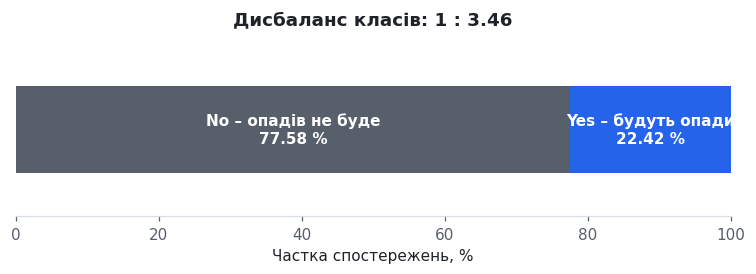

In [9]:
# --- Графік дисбалансу класів ---
fig, ax = plt.subplots(figsize=(7, 2.6))

shares = [share_no, share_yes]
labels = ["No – опадів не буде", "Yes – будуть опади"]
colors = [MUTED, PALETTE[0]]        # цільовий (міноритарний) клас виділяємо кольором

# Будуємо одну складену горизонтальну смугу: вона наочніше за два окремі
# стовпчики показує саме ПРОПОРЦІЮ класів, а не їхні абсолютні значення.
left = 0                             # накопичувач зміщення для наступного сегмента
for share, label, color in zip(shares, labels, colors):
    # left зсуває початок сегмента, щоб вони йшли один за одним без розривів
    ax.barh(0, share, left=left, color=color, height=.5)
    # Пряме підписування: значення пишемо на самій смузі, а не в легенді
    ax.text(left + share / 2, 0, f"{label}\n{share:.2f} %",
            ha="center", va="center", color="white", fontsize=10, fontweight="bold")
    left += share                    # зсуваємо старт для наступного сегмента

ax.set_xlim(0, 100)                  # шкала у відсотках: завжди повні 0-100
ax.set_ylim(-.5, .5)
ax.set_yticks([])                    # вісь Y не несе інформації – прибираємо підписи
ax.set_xlabel("Частка спостережень, %")
ax.grid(False)
ax.spines["left"].set_visible(False)
style_axes(ax, title=f"Дисбаланс класів: 1 : {n_no / n_yes:.2f}")
plt.tight_layout()
plt.show()


### Комірка 1.7 – допоміжна цільова змінна «сильні опади»

Формуємо другу, рідкіснішу цільову змінну: опади наступної доби понад заданий поріг.
Вона знадобиться в розділі 4, щоб порівняти поведінку методів аугментації за різної
тяжкості дисбалансу.

Беремо `Rainfall` **наступного дня** (зсув у межах кожної станції), інакше ціль
потрапила б у предиктори.

In [10]:
# --- Допоміжна цільова змінна: сильні опади наступної доби ---
HEAVY_MM = 25   # поріг сильних опадів, мм

# Сортуємо за станцією та датою – обов'язково перед зсувом
df = df.sort_values(["Location", DATE_COL]).reset_index(drop=True)

# shift(-1) у межах кожної станції = значення НАСТУПНОГО дня тієї самої станції.
# Без groupby ми б "склеїли" кінець однієї станції з початком іншої.
rain_next = df.groupby("Location")["Rainfall"].shift(-1)
df["HeavyRainTomorrow"] = (rain_next > HEAVY_MM).astype("float")
df.loc[rain_next.isna(), "HeavyRainTomorrow"] = np.nan   # останній день станції – мітки немає

heavy_share = df["HeavyRainTomorrow"].mean() * 100
same_day_share = (df["Rainfall"] > HEAVY_MM).mean() * 100

print(f"Частка днів з опадами > {HEAVY_MM} мм (поточна доба):   {same_day_share:.2f} %")
print(f"Допоміжна ціль HeavyRainTomorrow (наступна доба): {heavy_share:.2f} %")
print(f"  -> співвідношення класів 1 : {(100 - heavy_share) / heavy_share:.1f}")
print(f"\nБез мітки (останній день кожної станції): "
      f"{df['HeavyRainTomorrow'].isna().sum():,} записів".replace(",", " "))


Частка днів з опадами > 25 мм (поточна доба):   1.98 %
Допоміжна ціль HeavyRainTomorrow (наступна доба): 2.00 %
  -> співвідношення класів 1 : 48.9

Без мітки (останній день кожної станції): 1 453 записів


### Комірка 1.8 – хронологічний поділ вибірки

**Критично важливий крок, який виконується ДО будь-якої обробки даних.**

Дані є часовим рядом, згрупованим за метеостанціями. Випадковий поділ
(`train_test_split(shuffle=True)`) спричинив би **витік інформації**: сусідні дні
однієї станції майже ідентичні, тож модель «підглядала» б відповіді.

Тому ділимо хронологічно:

| Вибірка | Період | Призначення |
|---|---|---|
| Навчальна | ≤ 2015 | навчання моделей, підбір параметрів обробки |
| Валідаційна | 2016 | порівняння методів обробки та аугментації |
| Тестова | 2017 | фінальна незалежна оцінка |

Усі перетворювачі (`fit`) надалі навчаються **виключно на навчальній вибірці**.

In [11]:
# --- Хронологічний поділ вибірки ---
# Виділяємо рік зі стовпця дати – за ним і ділитимемо вибірку
df["year"] = df[DATE_COL].dt.year

# Межі підібрано так, щоб кожна вибірка містила ПОВНІ річні цикли:
# інакше в навчанні переважали б, скажімо, літні місяці, а в тесті – зимові,
# і різниця метрик пояснювалася б сезоном, а не якістю моделі.
train_mask = df["year"] <= 2015      # 2007-2015: навчання
valid_mask = df["year"] == 2016      # 2016: порівняння методів обробки
test_mask  = df["year"] >= 2017      # 2017: фінальна незалежна оцінка

# .copy() обов'язковий: без нього pandas поверне представлення (view),
# і подальше додавання стовпців спричинить SettingWithCopyWarning.
df_train = df[train_mask].copy()
df_valid = df[valid_mask].copy()
df_test  = df[test_mask].copy()

split_info = pd.DataFrame({
    "Вибірка": ["Навчальна (train)", "Валідаційна (valid)", "Тестова (test)"],
    "Період": ["2007–2015", "2016", "2017"],
    "Рядків": [len(df_train), len(df_valid), len(df_test)],
    "Частка, %": [round(len(x) / len(df) * 100, 1)
                  for x in (df_train, df_valid, df_test)],
    "Частка класу Yes, %": [round((x[TARGET] == "Yes").mean() * 100, 2)
                            for x in (df_train, df_valid, df_test)],
})
display(split_info)

print(f"Разом: {len(df_train) + len(df_valid) + len(df_test):,} = {len(df):,}".replace(",", " "))
print("\nУВАГА: усі подальші fit() виконуються ЛИШЕ на df_train.")


,Вибірка,Період,Рядків,"Частка, %","Частка класу Yes, %"
0,Навчальна (train),2007–2015,116219,81.7,22.31
1,Валідаційна (valid),2016,17508,12.3,23.89
2,Тестова (test),2017,8466,6.0,20.82


Разом: 142 193 = 142 193

УВАГА: усі подальші fit() виконуються ЛИШЕ на df_train.


---
# Розділ 2. Глибинний дослідницький аналіз (Advanced EDA)

**Завдання методички:**

1. **Аналіз розподілів та кореляцій** – матриці кореляцій Пірсона та Спірмена,
   виявлення мультиколінеарності; перевірка числових ознак на нормальність
   (візуально + тести Шапіро-Уїлка та Д'Агостіно).
2. **Аналіз аномалій та викидів** – порівняння IQR, Z-score та ансамблевого методу
   (Isolation Forest / Local Outlier Factor).

## 2.1. Описова статистика

### Комірка 2.1 – базові статистики числових ознак

Крім стандартних квантилів додаємо коефіцієнти **асиметрії** (skewness) та
**ексцесу** (kurtosis) – вони вказують, наскільки розподіл відхиляється від
нормального й чи потрібні степеневі перетворення.

In [12]:
# --- Описова статистика числових ознак ---
# .describe() дає квантилі, .T транспонує – ознаки стають рядками,
# так таблицю зручніше читати, коли ознак багато.
desc = df[NUM_FEATURES].describe().T

# Два показники форми розподілу, яких немає у describe():
desc["skew"] = df[NUM_FEATURES].skew()      # асиметрія: 0 – симетрично, >0 – хвіст праворуч
desc["kurtosis"] = df[NUM_FEATURES].kurt()  # ексцес: 0 – як у нормального; >0 – важкі хвости
desc["missing_%"] = df[NUM_FEATURES].isna().mean() * 100   # mean() від булевих = частка True

desc = desc[["count", "mean", "std", "min", "25%", "50%", "75%", "max",
             "skew", "kurtosis", "missing_%"]]
display(desc.round(2))


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,missing_%
MinTemp,141556.0,12.19,6.40,-8.5,7.6,12.0,16.8,33.9,0.02,-0.49,0.45
MaxTemp,141871.0,23.23,7.12,-4.8,17.9,22.6,28.2,48.1,0.22,-0.24,0.23
Rainfall,140787.0,2.35,8.47,0.0,0.0,0.0,0.8,371.0,9.89,180.00,0.99
Evaporation,81350.0,5.47,4.19,0.0,2.6,4.8,7.4,145.0,3.75,45.07,42.79
Sunshine,74377.0,7.62,3.78,0.0,4.9,8.5,10.6,14.5,-0.50,-0.82,47.69
WindGustSpeed,132923.0,39.98,13.59,6.0,31.0,39.0,48.0,135.0,0.87,1.42,6.52
WindSpeed9am,140845.0,14.00,8.89,0.0,7.0,13.0,19.0,130.0,0.78,1.23,0.95
WindSpeed3pm,139563.0,18.64,8.80,0.0,13.0,19.0,24.0,87.0,0.63,0.78,1.85
Humidity9am,140419.0,68.84,19.05,0.0,57.0,70.0,83.0,100.0,-0.48,-0.04,1.25
Humidity3pm,138583.0,51.48,20.80,0.0,37.0,52.0,66.0,100.0,0.03,-0.51,2.54


## 2.2. Аналіз пропущених значень

### Комірка 2.2 – таблиця та графік пропусків

Пропуски – ключова особливість цього датасету. Визначаємо їхній обсяг і структуру.

In [13]:
# --- Аналіз пропущених значень ---
# Характеризуємо набір даних у тому вигляді, в якому він опублікований,
# тому беремо ВИХІДНІ 23 стовпці (df_raw), а не робочу вибірку з доданими
# службовими ознаками (year, HeavyRainTomorrow).
ORIGINAL_COLS = df_raw.columns.tolist()

miss = pd.DataFrame({
    "Ознака": ORIGINAL_COLS,
    "Пропусків": df_raw.isna().sum().values,
    "Частка, %": (df_raw.isna().mean() * 100).round(2).values,
})
miss = miss[miss["Пропусків"] > 0].sort_values("Частка, %", ascending=False)
miss = miss.reset_index(drop=True)
display(miss)

rows_any_na = df_raw.isna().any(axis=1).mean() * 100
complete_rows = (~df_raw.isna().any(axis=1)).sum()

print(f"Стовпців із пропусками: {len(miss)} із {len(ORIGINAL_COLS)}")
print(f"Рядків із щонайменше одним пропуском: {rows_any_na:.1f} %")
print(f"Повністю заповнених рядків: {complete_rows:,}".replace(",", " "),
      f"({complete_rows / len(df_raw) * 100:.1f} %)")


,Ознака,Пропусків,"Частка, %"
0,Sunshine,69835,48.01
1,Evaporation,62790,43.17
2,Cloud3pm,59358,40.81
3,Cloud9am,55888,38.42
4,Pressure9am,15065,10.36
5,Pressure3pm,15028,10.33
6,WindDir9am,10566,7.26
7,WindGustDir,10326,7.10
8,WindGustSpeed,10263,7.06
9,Humidity3pm,4507,3.10


Стовпців із пропусками: 21 із 23
Рядків із щонайменше одним пропуском: 61.2 %
Повністю заповнених рядків: 56 420 (38.8 %)


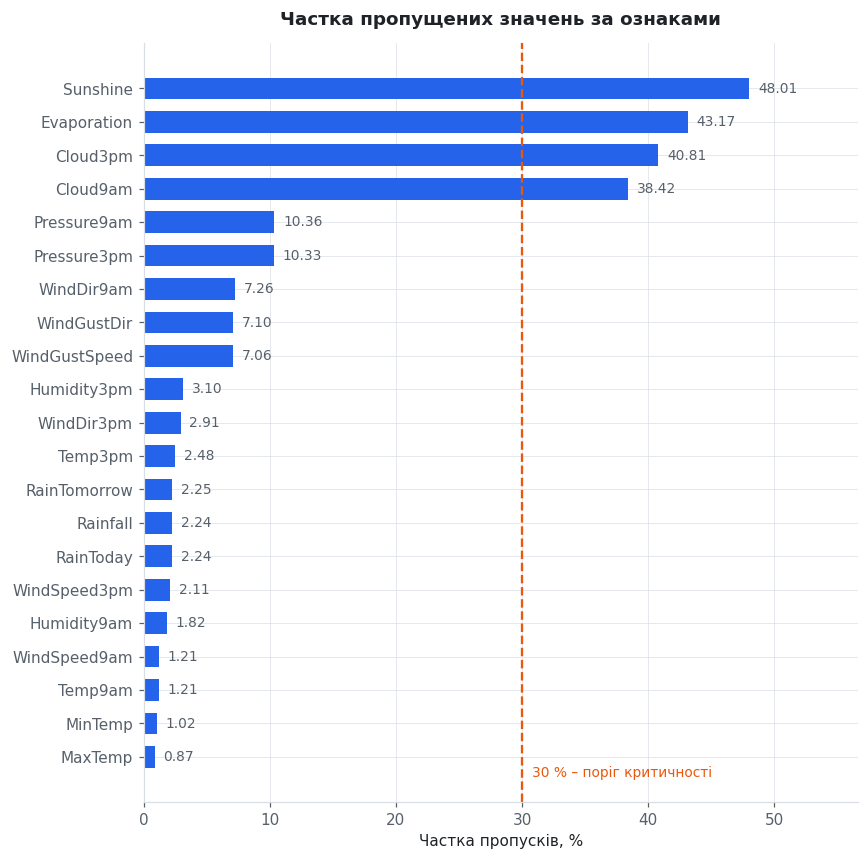

In [14]:
# --- Горизонтальна діаграма часток пропусків ---
# Одна серія -> легенда не потрібна; значення підписуємо прямо на смугах.
m = miss[miss["Частка, %"] > 0].iloc[::-1]       # знизу вгору за зростанням

fig, ax = plt.subplots(figsize=(8, .32 * len(m) + 1.2))
bars = ax.barh(m["Ознака"], m["Частка, %"], color=PALETTE[0], height=.65)

# Критичний поріг: понад 30 % пропусків -> ознака потребує особливої уваги
ax.axvline(30, color=PALETTE[1], linestyle="--", linewidth=1.5, zorder=1)
ax.text(30.8, -0.6, "30 % – поріг критичності", color=PALETTE[1], fontsize=9)

for bar, val in zip(bars, m["Частка, %"]):
    ax.text(val + .7, bar.get_y() + bar.get_height() / 2,
            f"{val:.2f}", va="center", fontsize=9, color=MUTED)

ax.set_xlim(0, max(m["Частка, %"]) * 1.18)
style_axes(ax, title="Частка пропущених значень за ознаками",
           xlabel="Частка пропусків, %", ylabel="")
plt.tight_layout()
plt.show()


### Комірка 2.3 – доведення механізму MNAR

Пропуски бувають трьох типів:

| Механізм | Розшифрування | Наслідок |
|---|---|---|
| **MCAR** | Missing Completely At Random | пропуск не залежить ні від чого; проста імпутація коректна |
| **MAR** | Missing At Random | пропуск залежить від **інших спостережуваних** ознак |
| **MNAR** | Missing Not At Random | пропуск залежить від **неспостережуваного** чинника |

Перевіряємо гіпотезу: пропуски `Sunshine` зумовлені не випадковістю, а **технічним
оснащенням конкретної метеостанції**. Якщо так – медіанна імпутація змішуватиме
кліматичні зони, і потрібні методи, що враховують контекст.

In [15]:
# --- Доведення механізму MNAR: пропуски залежать від метеостанції ---
mnar_cols = ["Sunshine", "Evaporation", "Cloud9am", "Cloud3pm"]

# Для кожної станції рахуємо частку пропусків по кожній ознаці
# Для КОЖНОЇ станції окремо рахуємо частку пропусків по кожній ознаці.
# Якби пропуски були випадковими (MCAR), ця частка була б приблизно однаковою
# для всіх станцій. Якщо ж вона розпадається на 0 % і 100 % – причина системна.
by_station = df.groupby("Location")[mnar_cols].apply(lambda g: g.isna().mean())

print("Розподіл станцій за часткою пропусків:\n")
summary = pd.DataFrame({
    "Ознака": mnar_cols,
    "Станцій без даних (100 % пропусків)": [(by_station[c] > .99).sum() for c in mnar_cols],
    "Станцій із повними даними (0 %)": [(by_station[c] < .01).sum() for c in mnar_cols],
    "Станцій із частковими даними": [((by_station[c] >= .01) & (by_station[c] <= .99)).sum()
                                     for c in mnar_cols],
})
summary["Усього станцій"] = df["Location"].nunique()
display(summary)

print(f"ВИСНОВОК: ознака Sunshine повністю відсутня на "
      f"{(by_station['Sunshine'] > .99).sum()} станціях із {df['Location'].nunique()} "
      f"і повністю наявна на {(by_station['Sunshine'] < .01).sum()}.")


Розподіл станцій за часткою пропусків:



,Ознака,Станцій без даних (100 % пропусків),Станцій із повними даними (0 %),Станцій із частковими даними,Усього станцій
0,Sunshine,19,10,20,49
1,Evaporation,16,7,26,49
2,Cloud9am,12,7,30,49
3,Cloud3pm,12,7,30,49


ВИСНОВОК: ознака Sunshine повністю відсутня на 19 станціях із 49 і повністю наявна на 10.


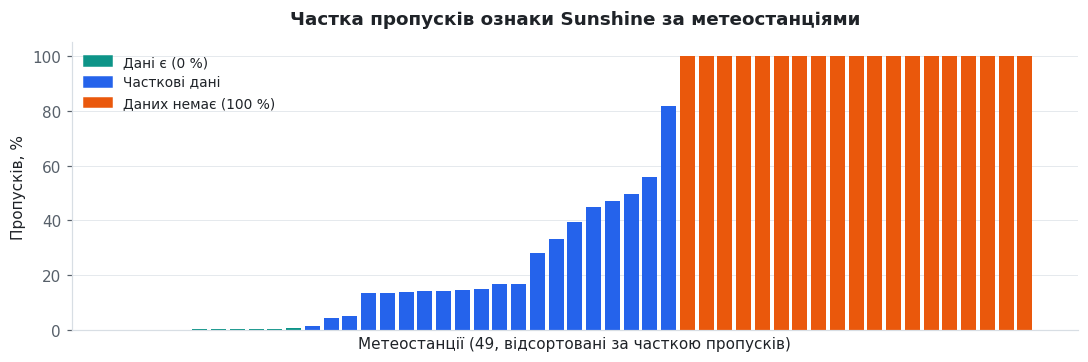

In [16]:
# --- Візуалізація: частка пропусків Sunshine по станціях ---
s = by_station["Sunshine"].sort_values() * 100

fig, ax = plt.subplots(figsize=(10, 3.4))
# Колір кодує три режими роботи станції – це стан, а не кількість,
# тому використовуємо дискретні кольори, а не градієнт.
colors = np.where(s > 99, PALETTE[1], np.where(s < 1, PALETTE[2], PALETTE[0]))
ax.bar(range(len(s)), s.values, color=colors, width=.8)

ax.set_xticks([])
ax.set_ylim(0, 105)
style_axes(ax, title="Частка пропусків ознаки Sunshine за метеостанціями",
           xlabel="Метеостанції (49, відсортовані за часткою пропусків)",
           ylabel="Пропусків, %")

# Легенда обов'язкова: три категорії, колір сам по собі значення не передає
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (PALETTE[2], PALETTE[0], PALETTE[1])]
ax.legend(handles, ["Дані є (0 %)", "Часткові дані", "Даних немає (100 %)"],
          loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()


## 2.3. Аналіз розподілів та перевірка нормальності

### Комірка 2.4 – гістограми числових ознак

Візуальна перевірка форми розподілу – перший крок перед застосуванням статистичних тестів.

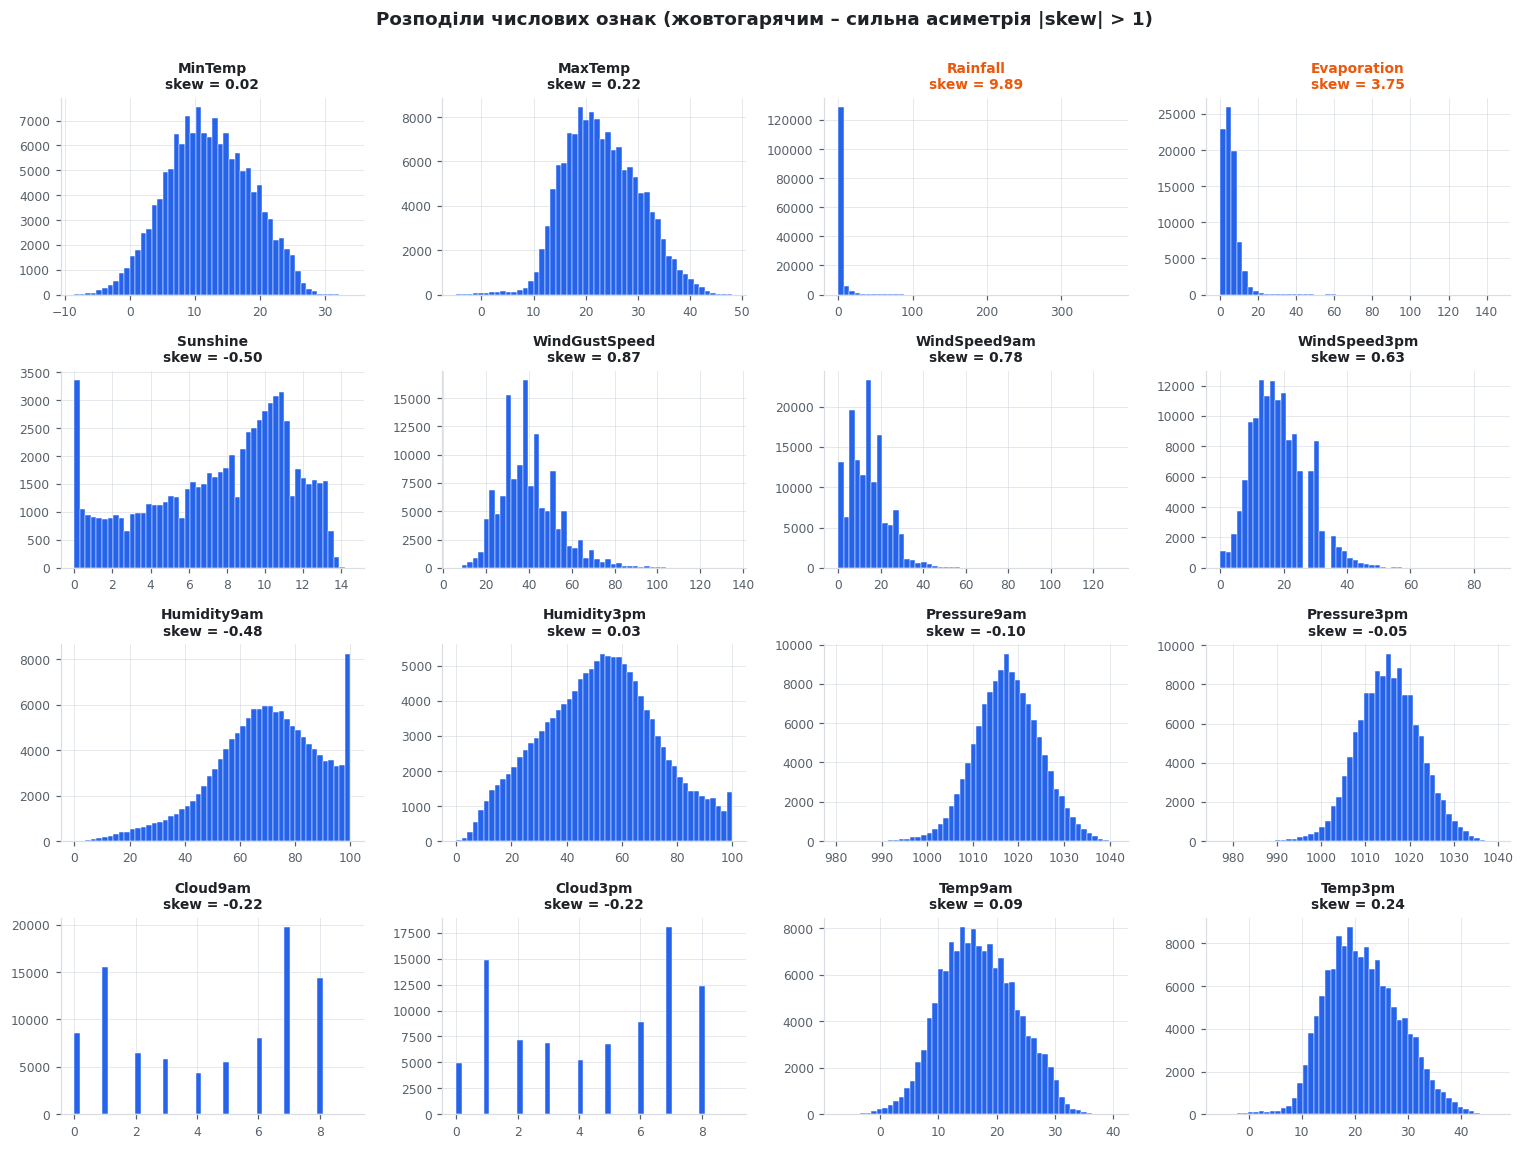

In [17]:
# --- Гістограми всіх числових ознак ---
n_cols = 4
n_rows = int(np.ceil(len(NUM_FEATURES) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 2.6 * n_rows))
axes = axes.ravel()

for ax, col in zip(axes, NUM_FEATURES):
    data = df[col].dropna()
    ax.hist(data, bins=50, color=PALETTE[0], edgecolor="white", linewidth=.3)
    sk = data.skew()
    # Асиметричні ознаки позначаємо кольором у заголовку
    ax.set_title(f"{col}\nskew = {sk:.2f}", fontsize=9,
                 color=PALETTE[1] if abs(sk) > 1 else INK)
    ax.tick_params(labelsize=8)
    ax.set_ylabel("")

for ax in axes[len(NUM_FEATURES):]:
    ax.set_visible(False)

fig.suptitle("Розподіли числових ознак (жовтогарячим – сильна асиметрія |skew| > 1)",
             fontsize=12, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()


### Комірка 2.5 – Q-Q графіки

**Q-Q графік** (квантиль-квантиль) порівнює квантилі емпіричного розподілу з квантилями
теоретичного нормального. Якщо точки лягають на пряму – розподіл близький до нормального;
відхилення на кінцях свідчать про «важкі хвости» або асиметрію.

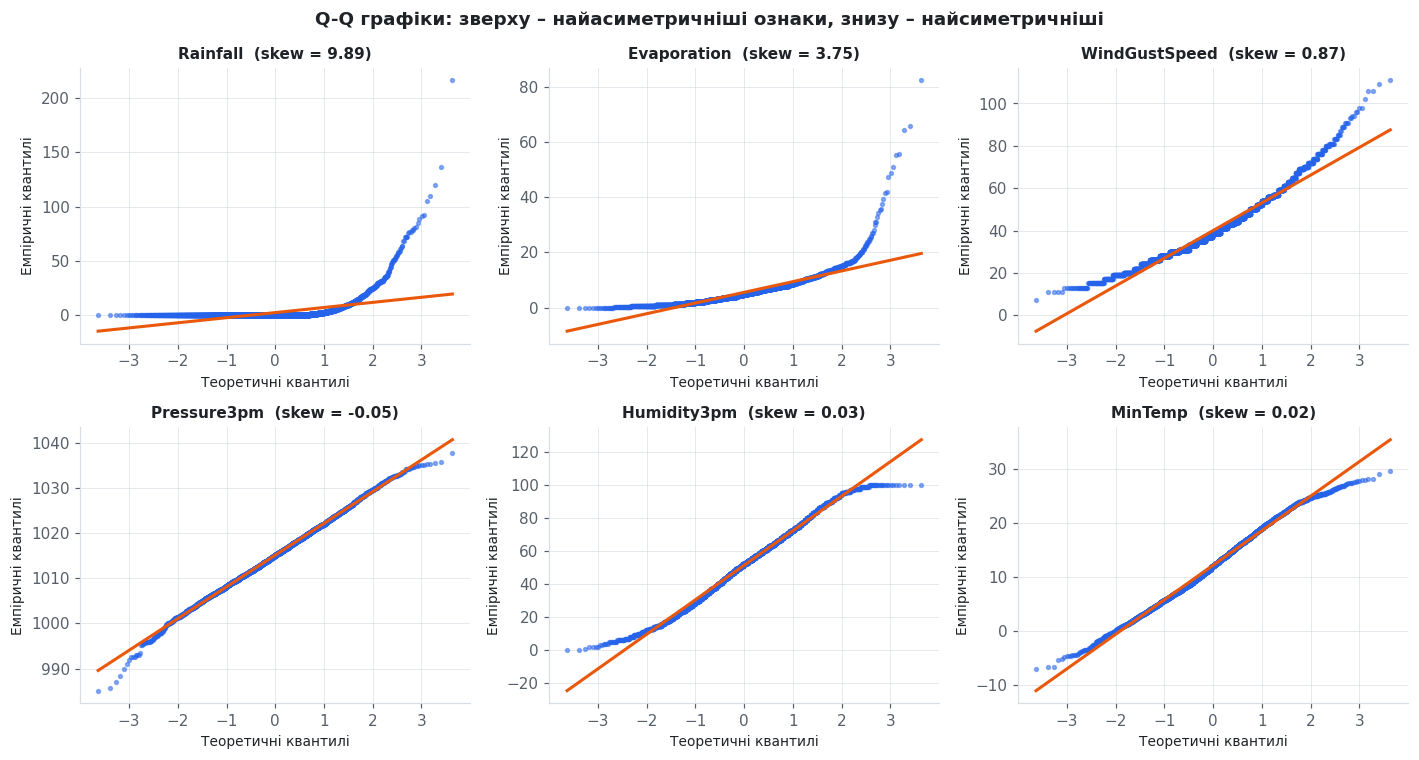

In [18]:
# --- Q-Q графіки для найбільш і найменш асиметричних ознак ---
skews = df[NUM_FEATURES].skew().abs().sort_values(ascending=False)
# Беремо 3 найасиметричніші та 3 найсиметричніші ознаки
qq_cols = list(skews.index[:3]) + list(skews.index[-3:])

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), qq_cols):
    # Вибірка 5000 точок: Q-Q графік на 140k точок нечитабельний і повільний
    data = df[col].dropna().sample(min(5000, df[col].notna().sum()),
                                   random_state=RANDOM_STATE)
    stats.probplot(data, dist="norm", plot=ax)
    ax.get_lines()[0].set(marker="o", markersize=2.5, color=PALETTE[0], alpha=.5)
    ax.get_lines()[1].set(color=PALETTE[1], linewidth=2)   # теоретична пряма
    ax.set_title(f"{col}  (skew = {df[col].skew():.2f})", fontsize=10)
    ax.set_xlabel("Теоретичні квантилі", fontsize=9)
    ax.set_ylabel("Емпіричні квантилі", fontsize=9)

fig.suptitle("Q-Q графіки: зверху – найасиметричніші ознаки, знизу – найсиметричніші",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


### Комірка 2.6 – статистичні тести нормальності

Застосовуємо два тести з нульовою гіпотезою «вибірка з нормального розподілу»:

* **Шапіро-Уїлка** – потужний на малих вибірках; `scipy` обмежує його розміром
  5000 спостережень, тому беремо випадкову підвибірку;
* **Д'Агостіно-Пірсона** (`normaltest`) – комбінує асиметрію та ексцес, працює на всій вибірці.

Поряд із p-значенням виводимо коефіцієнти асиметрії та ексцесу: на великій вибірці
тести чутливі навіть до незначних відхилень, тому розмір ефекту потрібен для інтерпретації.

In [19]:
# --- Статистичні тести нормальності ---
ALPHA = 0.05         # рівень значущості
SHAPIRO_N = 5000     # обмеження scipy для тесту Шапіро-Уїлка

rows = []
for col in NUM_FEATURES:
    data = df[col].dropna()

    # Тест Шапіро-Уїлка на підвибірці
    sample = data.sample(min(SHAPIRO_N, len(data)), random_state=RANDOM_STATE)
    w_stat, p_shapiro = stats.shapiro(sample)

    # Тест Д'Агостіно-Пірсона на всіх даних
    k2_stat, p_dagostino = stats.normaltest(data)

    rows.append({
        "Ознака": col,
        "Шапіро W": round(w_stat, 4),
        "p (Шапіро)": p_shapiro,
        "K² Д'Агостіно": round(k2_stat, 1),
        "p (Д'Агостіно)": p_dagostino,
        "Асиметрія": round(data.skew(), 2),
        "Ексцес": round(data.kurt(), 2),
        "Нормальний?": "так" if min(p_shapiro, p_dagostino) > ALPHA else "ні",
    })

norm_tests = pd.DataFrame(rows)
# Форматуємо p-значення у науковій нотації
fmt = norm_tests.copy()
fmt["p (Шапіро)"] = fmt["p (Шапіро)"].map(lambda v: f"{v:.2e}")
fmt["p (Д'Агостіно)"] = fmt["p (Д'Агостіно)"].map(lambda v: f"{v:.2e}")
display(fmt)

n_normal = (norm_tests["Нормальний?"] == "так").sum()
print(f"Розподіл визнано нормальним: {n_normal} із {len(NUM_FEATURES)} ознак "
      f"(рівень значущості alpha = {ALPHA})")


,Ознака,Шапіро W,p (Шапіро),K² Д'Агостіно,p (Д'Агостіно),Асиметрія,Ексцес,Нормальний?
0,MinTemp,0.9946,8.09e-13,2541.9,0.00e+00,0.02,-0.49,ні
1,MaxTemp,0.9907,1.42e-17,1602.8,0.00e+00,0.22,-0.24,ні
2,Rainfall,0.2851,4.53e-88,220047.4,0.00e+00,9.89,180.00,ні
3,Evaporation,0.7478,4.74e-66,71024.7,0.00e+00,3.75,45.07,ні
4,Sunshine,0.9408,8.60e-41,9770.6,0.00e+00,-0.50,-0.82,ні
5,WindGustSpeed,0.9611,1.21e-34,16870.8,0.00e+00,0.87,1.42,ні
6,WindSpeed9am,0.9590,2.15e-35,14773.8,0.00e+00,0.78,1.23,ні
7,WindSpeed3pm,0.9701,4.76e-31,9726.7,0.00e+00,0.63,0.78,ні
8,Humidity9am,0.9779,3.51e-27,4926.8,0.00e+00,-0.48,-0.04,ні
9,Humidity3pm,0.9928,3.56e-15,2851.3,0.00e+00,0.03,-0.51,ні


Розподіл визнано нормальним: 0 із 16 ознак (рівень значущості alpha = 0.05)


## 2.4. Кореляційний аналіз

### Комірка 2.7 – матриця кореляцій Пірсона

**Коефіцієнт Пірсона** вимірює силу *лінійного* зв'язку:

$$r_{xy} = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \sum (y_i - \bar{y})^2}}$$

Чутливий до викидів і припускає лінійність зв'язку.

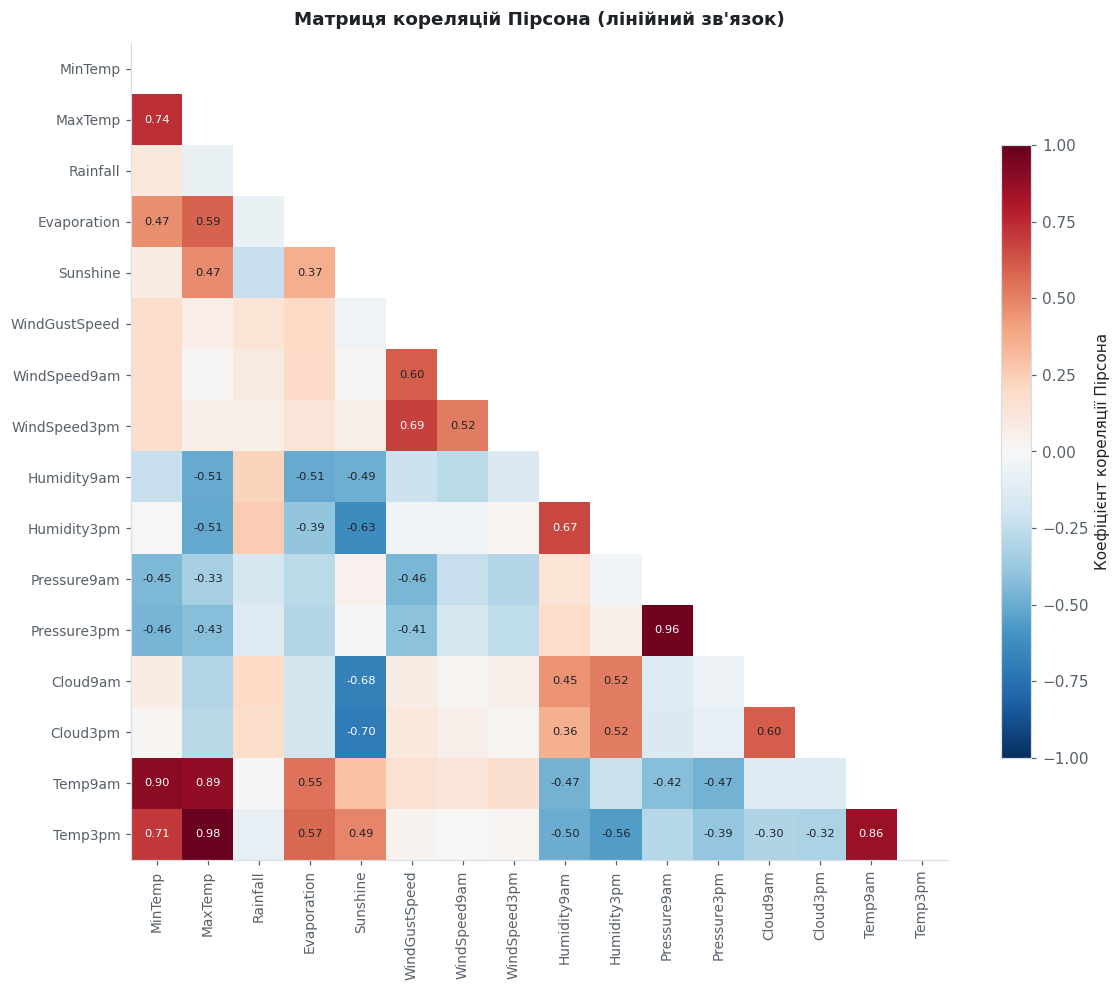

In [20]:
# --- Матриця кореляцій Пірсона ---
corr_p = df[NUM_FEATURES].corr(method="pearson")

# Маска для верхнього трикутника: матриця симетрична, показувати обидві половини зайво
mask = np.triu(np.ones_like(corr_p, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
# ДИВЕРГЕНТНА шкала: кореляція має знак, тому два полюси й нейтральна середина на 0
im = ax.imshow(np.where(mask, np.nan, corr_p), cmap=CMAP_DIV, vmin=-1, vmax=1)

ax.set_xticks(range(len(NUM_FEATURES)))
ax.set_yticks(range(len(NUM_FEATURES)))
ax.set_xticklabels(NUM_FEATURES, rotation=90, fontsize=9)
ax.set_yticklabels(NUM_FEATURES, fontsize=9)
ax.grid(False)

# Підписуємо лише помітні кореляції (|r| > 0.3), щоб не захаращувати матрицю
for i in range(len(NUM_FEATURES)):
    for j in range(i):
        v = corr_p.iloc[i, j]
        if abs(v) > .3:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                    color="white" if abs(v) > .65 else INK)

cbar = fig.colorbar(im, ax=ax, shrink=.75)
cbar.set_label("Коефіцієнт кореляції Пірсона", fontsize=10)
style_axes(ax, title="Матриця кореляцій Пірсона (лінійний зв'язок)")
plt.tight_layout()
plt.show()


### Комірка 2.8 – матриця кореляцій Спірмена

**Коефіцієнт Спірмена** – це коефіцієнт Пірсона, обчислений на **рангах** замість
самих значень. Він вимірює *монотонний* зв'язок, стійкий до викидів і не вимагає
нормальності. Для сильно асиметричних ознак (як `Rainfall`) він надійніший.

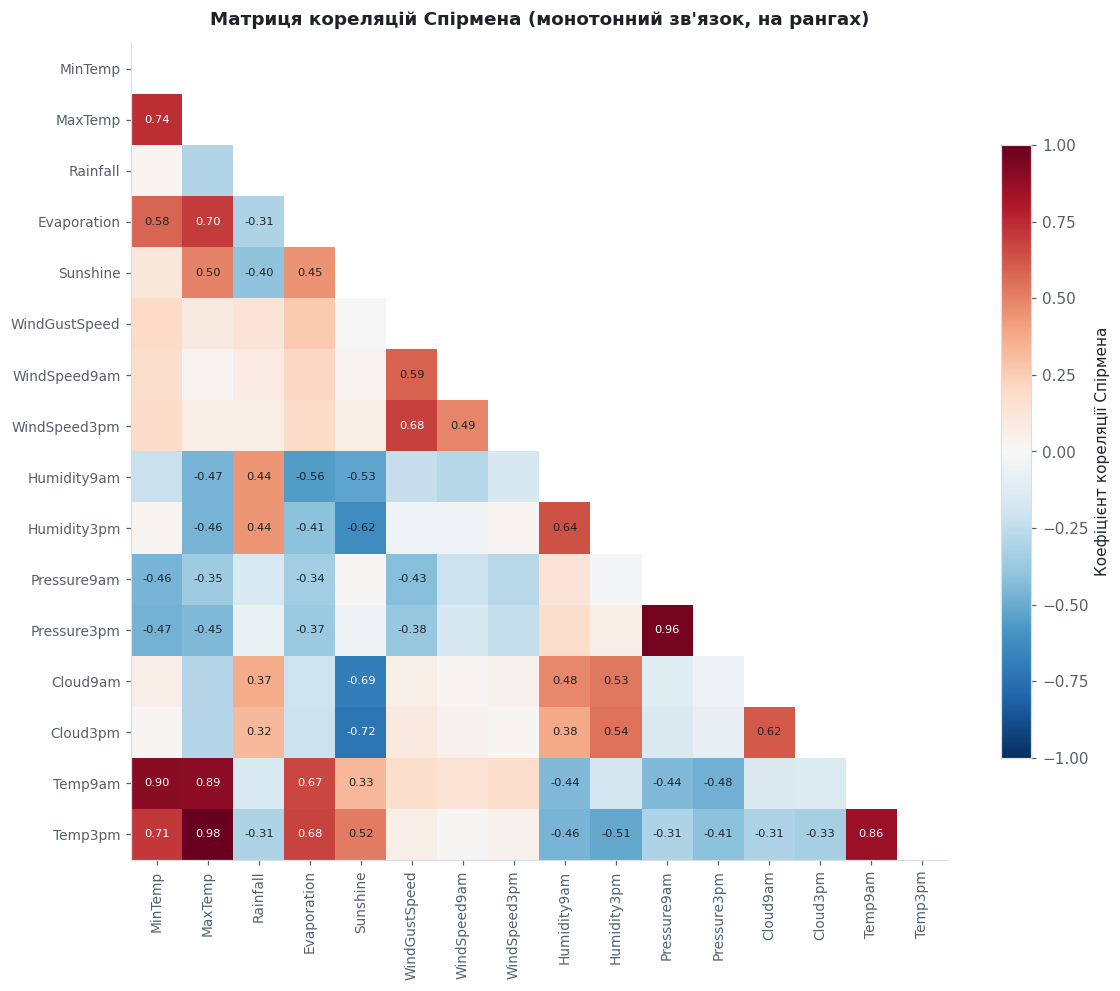

In [21]:
# --- Матриця кореляцій Спірмена ---
# method="spearman" – pandas спершу замінює значення їхніми РАНГАМИ,
# а вже потім рахує звичайну кореляцію Пірсона на цих рангах.
corr_s = df[NUM_FEATURES].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9))
# mask (створена вище) ховає верхній трикутник; np.nan малюється порожнім.
# vmin/vmax жорстко фіксуємо на -1 і 1, щоб нейтральний колір припав саме на 0,
# інакше шкала "попливе" й слабка кореляція виглядатиме сильною.
im = ax.imshow(np.where(mask, np.nan, corr_s), cmap=CMAP_DIV, vmin=-1, vmax=1)

ax.set_xticks(range(len(NUM_FEATURES)))
ax.set_yticks(range(len(NUM_FEATURES)))
ax.set_xticklabels(NUM_FEATURES, rotation=90, fontsize=9)
ax.set_yticklabels(NUM_FEATURES, fontsize=9)
ax.grid(False)

for i in range(len(NUM_FEATURES)):
    for j in range(i):
        v = corr_s.iloc[i, j]
        if abs(v) > .3:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                    color="white" if abs(v) > .65 else INK)

cbar = fig.colorbar(im, ax=ax, shrink=.75)
cbar.set_label("Коефіцієнт кореляції Спірмена", fontsize=10)
style_axes(ax, title="Матриця кореляцій Спірмена (монотонний зв'язок, на рангах)")
plt.tight_layout()
plt.show()


### Комірка 2.9 – зіставлення Пірсона та Спірмена

Велика розбіжність між коефіцієнтами вказує на **нелінійність** зв'язку або
на вплив **викидів**: Пірсон на них реагує, Спірмен – ні.

In [22]:
# --- Топ пар за силою зв'язку та розбіжність між методами ---
def top_pairs(corr, k=10):
    """Повертає k пар ознак із найбільшим за модулем коефіцієнтом кореляції."""
    # k=1 у np.triu відкидає й головну діагональ (кореляція ознаки із собою = 1),
    # інакше вона посіла б перші місця рейтингу.
    m = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    # .stack() розгортає матрицю у Series з мультиіндексом (ознака1, ознака2)
    s = m.stack()
    # Сортуємо за МОДУЛЕМ: сильний від'ємний зв'язок не менш важливий за додатний,
    # але повертаємо значення зі знаком, щоб не втратити напрямок.
    return s.reindex(s.abs().sort_values(ascending=False).index)[:k]

tp = top_pairs(corr_p, 10)
pairs = pd.DataFrame({
    "Ознака 1": [i[0] for i in tp.index],
    "Ознака 2": [i[1] for i in tp.index],
    "Пірсон": tp.values.round(3),
    "Спірмен": [corr_s.loc[a, b].round(3) for a, b in tp.index],
})
pairs["|різниця|"] = (pairs["Пірсон"] - pairs["Спірмен"]).abs().round(3)
display(pairs)


,Ознака 1,Ознака 2,Пірсон,Спірмен,|різниця|
0,MaxTemp,Temp3pm,0.985,0.985,0.000
1,Pressure9am,Pressure3pm,0.961,0.960,0.001
2,MinTemp,Temp9am,0.902,0.899,0.003
3,MaxTemp,Temp9am,0.887,0.892,0.005
4,Temp9am,Temp3pm,0.861,0.865,0.004
5,MinTemp,MaxTemp,0.736,0.738,0.002
6,MinTemp,Temp3pm,0.709,0.710,0.001
7,Sunshine,Cloud3pm,-0.704,-0.719,0.015
8,WindGustSpeed,WindSpeed3pm,0.686,0.681,0.005
9,Sunshine,Cloud9am,-0.676,-0.688,0.012


### Комірка 2.10 – виявлення мультиколінеарності (VIF)

**Коефіцієнт інфляції дисперсії** (Variance Inflation Factor) показує, наскільки
зростає дисперсія оцінки коефіцієнта через корельованість ознаки з рештою:

$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$

де $R_j^2$ – коефіцієнт детермінації регресії ознаки $j$ на всі інші ознаки.

Обчислювати через окремі регресії повільно. Використовуємо еквівалентну властивість:
для стандартизованих ознак **VIF дорівнює діагоналі оберненої кореляційної матриці**,
$\text{VIF} = \text{diag}(R^{-1})$ – одна операція замість 16 регресій.

**Інтерпретація:** VIF < 5 – прийнятно; 5–10 – помірна мультиколінеарність;
> 10 – висока, ознака майже повністю пояснюється іншими.

In [23]:
# --- Обчислення VIF ---
def compute_vif(frame, cols):
    """VIF через діагональ оберненої кореляційної матриці: VIF = diag(R^-1).

    Еквівалентно формулі 1/(1-R_j^2), але обчислюється однією операцією.
    """
    # dropna() обов'язковий: кореляційна матриця з пропусками може виявитися
    # невід'ємно визначеною не повністю, і обернення її зламається.
    R = frame[cols].dropna().corr().values
    # np.linalg.inv обертає матрицю; діагональ оберненої і є вектором VIF
    vif = np.diag(np.linalg.inv(R))
    return pd.Series(vif, index=cols).sort_values(ascending=False)

vif_series = compute_vif(df, NUM_FEATURES)

vif_tbl = pd.DataFrame({
    "Ознака": vif_series.index,
    "VIF": vif_series.values.round(2),
})
# R^2 відновлюємо з VIF зворотною формулою – показує частку поясненої дисперсії
vif_tbl["R² з іншими ознаками"] = (1 - 1 / vif_tbl["VIF"]).round(3)
vif_tbl["Оцінка"] = pd.cut(vif_tbl["VIF"], [0, 5, 10, np.inf],
                           labels=["прийнятно", "помірна", "висока"])
display(vif_tbl)

high = vif_tbl[vif_tbl["VIF"] > 10]
print(f"Ознак із високою мультиколінеарністю (VIF > 10): {len(high)} із {len(NUM_FEATURES)}")
for _, r in high.iterrows():
    print(f"  {r['Ознака']:<16} VIF = {r['VIF']:>6.2f}  "
          f"(R² = {r['R² з іншими ознаками']:.3f} – пояснюється іншими ознаками)")


,Ознака,VIF,R² з іншими ознаками,Оцінка
0,Temp3pm,56.35,0.982,висока
1,MaxTemp,47.13,0.979,висока
2,Temp9am,24.65,0.959,висока
3,Pressure9am,20.16,0.950,висока
4,Pressure3pm,20.13,0.950,висока
5,MinTemp,11.01,0.909,висока
6,Humidity3pm,6.81,0.853,помірна
7,Humidity9am,4.46,0.776,прийнятно
8,Sunshine,3.34,0.701,прийнятно
9,WindGustSpeed,2.90,0.655,прийнятно


Ознак із високою мультиколінеарністю (VIF > 10): 6 із 16
  Temp3pm          VIF =  56.35  (R² = 0.982 – пояснюється іншими ознаками)
  MaxTemp          VIF =  47.13  (R² = 0.979 – пояснюється іншими ознаками)
  Temp9am          VIF =  24.65  (R² = 0.959 – пояснюється іншими ознаками)
  Pressure9am      VIF =  20.16  (R² = 0.950 – пояснюється іншими ознаками)
  Pressure3pm      VIF =  20.13  (R² = 0.950 – пояснюється іншими ознаками)
  MinTemp          VIF =  11.01  (R² = 0.909 – пояснюється іншими ознаками)


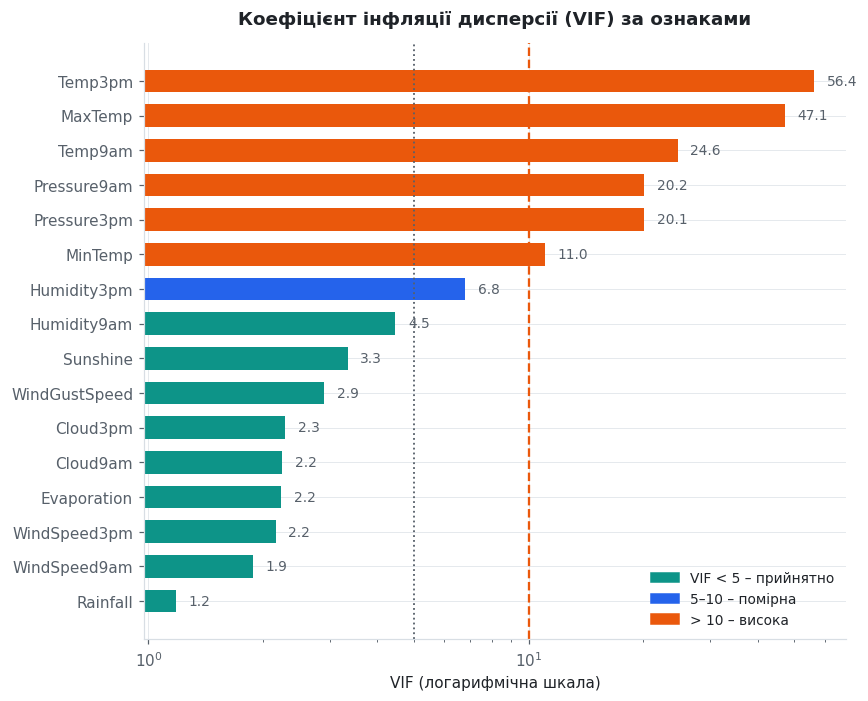

In [24]:
# --- Візуалізація VIF ---
v = vif_tbl.iloc[::-1]       # знизу вгору за зростанням

fig, ax = plt.subplots(figsize=(8, .33 * len(v) + 1.2))
# Колір кодує СТАН (прийнятно / помірна / висока), а не величину
col_map = {"прийнятно": PALETTE[2], "помірна": PALETTE[0], "висока": PALETTE[1]}
bars = ax.barh(v["Ознака"], v["VIF"], color=[col_map[x] for x in v["Оцінка"]], height=.65)

ax.axvline(5, color=MUTED, linestyle=":", linewidth=1.2)
ax.axvline(10, color=PALETTE[1], linestyle="--", linewidth=1.5)
ax.set_xscale("log")   # логарифмічна шкала: значення різняться на порядки

for bar, val in zip(bars, v["VIF"]):
    ax.text(val * 1.08, bar.get_y() + bar.get_height() / 2,
            f"{val:.1f}", va="center", fontsize=9, color=MUTED)

handles = [plt.Rectangle((0, 0), 1, 1, color=col_map[k]) for k in
           ["прийнятно", "помірна", "висока"]]
ax.legend(handles, ["VIF < 5 – прийнятно", "5–10 – помірна", "> 10 – висока"],
          loc="lower right", fontsize=9)
style_axes(ax, title="Коефіцієнт інфляції дисперсії (VIF) за ознаками",
           xlabel="VIF (логарифмічна шкала)", ylabel="")
plt.tight_layout()
plt.show()


### Комірка 2.11 – зв'язок між категоріальними ознаками (V Крамера)

Для категоріальних ознак коефіцієнт Пірсона незастосовний. Використовуємо **V Крамера** –
нормовану міру зв'язку на основі статистики $\chi^2$:

$$V = \sqrt{\frac{\chi^2 / n}{\min(k-1,\ r-1)}}$$

Значення від 0 (незалежні) до 1 (функціональна залежність). Застосовуємо поправку на зміщення.

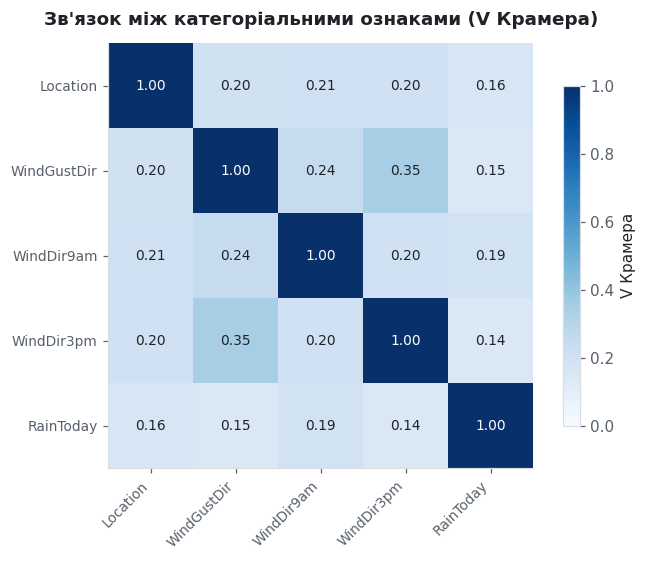

In [25]:
# --- V Крамера для категоріальних ознак ---
def cramers_v(x, y):
    """V Крамера з поправкою на зміщення (Bergsma, 2013)."""
    ct = pd.crosstab(x, y)                 # таблиця спряженості (частоти пар значень)
    # [0] – беремо саму статистику хі-квадрат; correction=False вимикає поправку
    # Єйтса, бо вона визначена лише для таблиць 2x2.
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()                    # загальна кількість спостережень
    r, k = ct.shape                        # кількість рядків і стовпців таблиці
    phi2 = chi2 / n                        # нормуємо хі-квадрат на обсяг вибірки
    # Поправка на зміщення для малих вибірок
    phi2_corr = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    r_corr = r - (r - 1) ** 2 / (n - 1)
    k_corr = k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2_corr / max(min(k_corr - 1, r_corr - 1), 1e-12))

cat_corr = pd.DataFrame(index=CAT_FEATURES, columns=CAT_FEATURES, dtype=float)
for a in CAT_FEATURES:
    for b in CAT_FEATURES:
        sub = df[[a, b]].dropna()
        cat_corr.loc[a, b] = 1.0 if a == b else cramers_v(sub[a], sub[b])

fig, ax = plt.subplots(figsize=(6.5, 5.2))
# V Крамера невід'ємний -> ПОСЛІДОВНА одноколірна шкала (не дивергентна)
im = ax.imshow(cat_corr.values.astype(float), cmap=CMAP_SEQ, vmin=0, vmax=1)
ax.set_xticks(range(len(CAT_FEATURES)))
ax.set_yticks(range(len(CAT_FEATURES)))
ax.set_xticklabels(CAT_FEATURES, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(CAT_FEATURES, fontsize=9)
ax.grid(False)
for i in range(len(CAT_FEATURES)):
    for j in range(len(CAT_FEATURES)):
        v = cat_corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if v > .6 else INK)
fig.colorbar(im, ax=ax, shrink=.8).set_label("V Крамера", fontsize=10)
style_axes(ax, title="Зв'язок між категоріальними ознаками (V Крамера)")
plt.tight_layout()
plt.show()


## 2.5. Аналіз аномалій та викидів

### Комірка 2.12 – чотири підходи до виявлення викидів

Порівнюємо методи, що спираються на різні припущення:

| Метод | Тип | Принцип | Припущення |
|---|---|---|---|
| **IQR** | одновимірний | за межами $[Q_1 - 1{,}5\,\text{IQR};\ Q_3 + 1{,}5\,\text{IQR}]$ | жодних (непараметричний) |
| **Z-score** | одновимірний | $\lvert z \rvert > 3$, де $z = (x-\mu)/\sigma$ | **нормальність розподілу** |
| **Isolation Forest** | багатовимірний, ансамблевий | аномалії ізолюються меншою кількістю розбиттів дерева | жодних |
| **Local Outlier Factor** | багатовимірний, локальний | порівнює локальну щільність точки зі щільністю сусідів | жодних |

Одновимірні методи бачать кожну ознаку окремо; багатовимірні виявляють аномальні
**комбінації** нормальних значень.

In [26]:
# --- Метод 1: межквартильний інтервал (IQR) ---
Q1 = df[NUM_FEATURES].quantile(.25)          # перший квартиль
Q3 = df[NUM_FEATURES].quantile(.75)          # третій квартиль
IQR = Q3 - Q1                                # міжквартильний розмах

# Множник 1.5 – класичне правило Тьюкі. Для нормального розподілу ці межі
# відсікають приблизно 0.7 % спостережень; для асиметричних – значно більше.
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
# Порівняння DataFrame із Series зіставляє їх за іменами стовпців – виходить
# булева матриця того ж розміру, де True означає "значення поза межами".
iqr_mask_per_col = (df[NUM_FEATURES] < lower) | (df[NUM_FEATURES] > upper)
iqr_outliers = iqr_mask_per_col.any(axis=1)  # axis=1 -> рядок-викид, якщо хоч одна ознака поза межами

iqr_tbl = pd.DataFrame({
    "Ознака": NUM_FEATURES,
    "Нижня межа": lower.round(2).values,
    "Верхня межа": upper.round(2).values,
    "Викидів": iqr_mask_per_col.sum().values,
    "Частка, %": (iqr_mask_per_col.mean() * 100).round(2).values,
})
display(iqr_tbl.sort_values("Частка, %", ascending=False).reset_index(drop=True))

print(f"Рядків, позначених як викид хоча б за однією ознакою: "
      f"{iqr_outliers.sum():,} ({iqr_outliers.mean() * 100:.2f} %)".replace(",", " "))


,Ознака,Нижня межа,Верхня межа,Викидів,"Частка, %"
0,Rainfall,-1.20,2.00,25228,17.74
1,WindGustSpeed,5.50,73.50,3006,2.11
2,WindSpeed3pm,-3.50,40.50,2458,1.73
3,Evaporation,-4.60,14.60,1954,1.37
4,WindSpeed9am,-11.00,37.00,1739,1.22
5,Humidity9am,18.00,122.00,1419,1.00
6,Pressure9am,998.65,1036.65,1174,0.83
7,Pressure3pm,996.00,1034.40,906,0.64
8,Temp3pm,1.90,41.10,735,0.52
9,MaxTemp,2.45,43.65,459,0.32


Рядків  позначених як викид хоча б за однією ознакою: 32 734 (23.02 %)


In [27]:
# --- Метод 2: Z-score ---
# z = (x - mu) / sigma; |z| > 3 означає відхилення понад 3 стандартні відхилення.
# Метод КОРЕКТНИЙ ЛИШЕ для приблизно нормальних розподілів (що ми спростували вище).
Z_THRESHOLD = 3

mu, sigma = df[NUM_FEATURES].mean(), df[NUM_FEATURES].std()
z_scores = (df[NUM_FEATURES] - mu) / sigma
z_mask_per_col = z_scores.abs() > Z_THRESHOLD
z_outliers = z_mask_per_col.any(axis=1)

z_tbl = pd.DataFrame({
    "Ознака": NUM_FEATURES,
    "Викидів": z_mask_per_col.sum().values,
    "Частка, %": (z_mask_per_col.mean() * 100).round(2).values,
})
display(z_tbl.sort_values("Частка, %", ascending=False).head(8).reset_index(drop=True))

print(f"Рядків-викидів за Z-score: {z_outliers.sum():,} "
      f"({z_outliers.mean() * 100:.2f} %)".replace(",", " "))


,Ознака,Викидів,"Частка, %"
0,Rainfall,2409,1.69
1,WindGustSpeed,1331,0.94
2,WindSpeed9am,1309,0.92
3,WindSpeed3pm,934,0.66
4,Evaporation,856,0.60
5,Pressure9am,499,0.35
6,Humidity9am,471,0.33
7,Pressure3pm,421,0.30


Рядків-викидів за Z-score: 7 144 (5.02 %)


In [28]:
# --- Методи 3 і 4: багатовимірні (Isolation Forest та LOF) ---
# Обидва не працюють із пропусками, тому для цього аналізу використовуємо
# ТИМЧАСОВУ медіанну імпутацію (лише щоб порівняти детектори викидів).
X_out = df[NUM_FEATURES].copy()
X_out = X_out.fillna(X_out.median())

CONTAMINATION = 0.05   # очікувана частка аномалій – задаємо однаковою для чесного порівняння

# --- Isolation Forest: ансамбль випадкових дерев ---
# Аномалію легше "відрізати" випадковими розбиттями, тому глибина її листа менша.
t0 = time.time()
iso = IsolationForest(n_estimators=200, contamination=CONTAMINATION,
                      random_state=RANDOM_STATE, n_jobs=-1)
iso_pred = iso.fit_predict(X_out)              # -1 = аномалія, 1 = норма
iso_outliers = pd.Series(iso_pred == -1, index=df.index)
iso_scores = -iso.score_samples(X_out)         # що більше, то аномальніше
t_iso = time.time() - t0

# --- Local Outlier Factor: порівняння локальної щільності ---
# LOF має складність O(n^2) за пам'яттю на сусідах, тому беремо підвибірку.
LOF_N = 20000
lof_idx = df.sample(min(LOF_N, len(df)), random_state=RANDOM_STATE).index
t0 = time.time()
lof = LocalOutlierFactor(n_neighbors=20, contamination=CONTAMINATION, n_jobs=-1)
lof_pred = lof.fit_predict(X_out.loc[lof_idx])
t_lof = time.time() - t0

lof_outliers = pd.Series(False, index=df.index)
lof_outliers.loc[lof_idx] = (lof_pred == -1)

print(f"Isolation Forest: {iso_outliers.sum():,} аномалій ".replace(",", " "),
      f"({iso_outliers.mean() * 100:.2f} %), час {t_iso:.1f} с, вибірка {len(X_out):,}".replace(",", " "))
print(f"LOF:              {lof_outliers.sum():,} аномалій ".replace(",", " "),
      f"({lof_pred.tolist().count(-1) / len(lof_idx) * 100:.2f} % від підвибірки), "
      f"час {t_lof:.1f} с, вибірка {len(lof_idx):,}".replace(",", " "))


Isolation Forest: 7 110 аномалій  (5.00 %)  час 4.0 с  вибірка 142 193
LOF:              1 000 аномалій  (5.00 % від підвибірки)  час 3.4 с  вибірка 20 000


### Комірка 2.13 – порівняння методів та міра збігу

Щоб кількісно оцінити, наскільки методи згодні між собою, обчислюємо
**коефіцієнт Жаккара** для кожної пари:

$$J(A,B) = \frac{|A \cap B|}{|A \cup B|}$$

Значення 1 означає повний збіг множин викидів, 0 – відсутність спільних елементів.

,Метод,Тип,Викидів,"Частка, %",Припущення
0,IQR (1.5×),одновимірний,32734,23.02,немає
1,Z-score (|z|>3),одновимірний,7144,5.02,нормальність
2,Isolation Forest,багатовимірний,7110,5.00,немає
3,LOF (підвибірка),багатовимірний,1000,0.70,немає


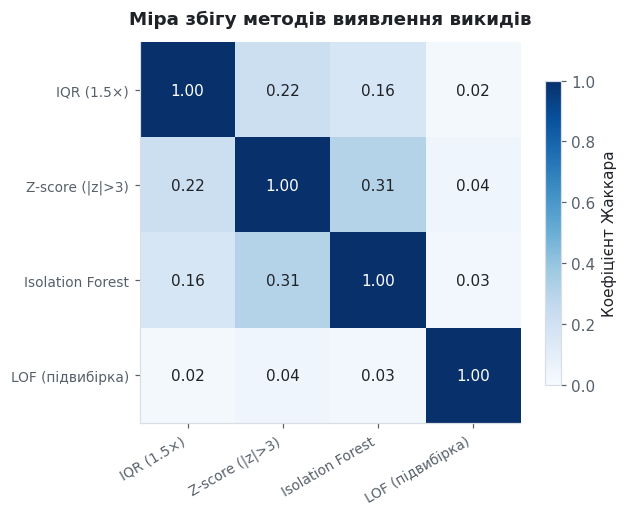

Середній збіг між різними методами: 0.13


In [29]:
# --- Порівняльна таблиця методів виявлення викидів ---
methods = {
    "IQR (1.5×)": iqr_outliers,
    "Z-score (|z|>3)": z_outliers,
    "Isolation Forest": iso_outliers,
    "LOF (підвибірка)": lof_outliers,
}

compare = pd.DataFrame({
    "Метод": list(methods),
    "Тип": ["одновимірний", "одновимірний", "багатовимірний", "багатовимірний"],
    "Викидів": [m.sum() for m in methods.values()],
    "Частка, %": [round(m.mean() * 100, 2) for m in methods.values()],
    "Припущення": ["немає", "нормальність", "немає", "немає"],
})
display(compare)

def jaccard(a, b):
    """Коефіцієнт Жаккара: частка спільних елементів у об'єднанні."""
    inter = (a & b).sum()      # потужність перетину: обидва методи назвали рядок викидом
    union = (a | b).sum()      # потужність об'єднання: хоча б один метод назвав
    # Захист від ділення на нуль, якщо жоден метод нічого не знайшов
    return inter / union if union else 0.0

names = list(methods)
J = pd.DataFrame(
    [[jaccard(methods[a], methods[b]) for b in names] for a in names],
    index=names, columns=names,
)

fig, ax = plt.subplots(figsize=(6, 4.8))
im = ax.imshow(J.values, cmap=CMAP_SEQ, vmin=0, vmax=1)   # міра згоди невід'ємна
ax.set_xticks(range(len(names)))
ax.set_yticks(range(len(names)))
ax.set_xticklabels(names, rotation=30, ha="right", fontsize=9)
ax.set_yticklabels(names, fontsize=9)
ax.grid(False)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{J.iloc[i, j]:.2f}", ha="center", va="center", fontsize=10,
                color="white" if J.iloc[i, j] > .6 else INK)
fig.colorbar(im, ax=ax, shrink=.8).set_label("Коефіцієнт Жаккара", fontsize=10)
style_axes(ax, title="Міра збігу методів виявлення викидів")
plt.tight_layout()
plt.show()

# Беремо лише позадіагональні елементи: діагональ – це збіг методу із самим
# собою, вона завжди дорівнює 1 і завищила б середнє.
off_diag = J.values[~np.eye(len(names), dtype=bool)]
print(f"Середній збіг між різними методами: {off_diag.mean():.2f}")


### Комірка 2.14 – рішення щодо викидів

Перевіряємо, чи відрізняється розподіл цільової змінної серед аномальних
і звичайних спостережень, і зберігаємо оцінку аномальності Isolation Forest
як нову ознаку (підхід «аномалія як ознака»).

In [30]:
# --- Перевірка: чи пов'язані викиди з цільовою змінною? ---
rate_normal = (df.loc[~iso_outliers, TARGET] == "Yes").mean() * 100
rate_outlier = (df.loc[iso_outliers, TARGET] == "Yes").mean() * 100

print("Частка дощових днів серед:")
print(f"  звичайних спостережень: {rate_normal:.2f} %")
print(f"  аномальних (Isolation Forest): {rate_outlier:.2f} %")
print(f"  різниця: {rate_outlier - rate_normal:+.2f} в. п.")

# Зберігаємо оцінку аномальності як майбутню ознаку (використаємо в розділі 4)
df["anomaly_score"] = iso_scores

# Підвибірки train/valid/test створено в розділі 1, тому нову ознаку
# потрібно перенести і в них (індекси успадковані від df).
for part in (df_train, df_valid, df_test):
    part["anomaly_score"] = df.loc[part.index, "anomaly_score"].values

print(f"\nОцінку аномальності збережено в ознаці 'anomaly_score' "
      f"(діапазон {iso_scores.min():.3f} … {iso_scores.max():.3f}).")
print("Ознаку перенесено також у навчальну, валідаційну та тестову вибірки.")


Частка дощових днів серед:
  звичайних спостережень: 21.16 %
  аномальних (Isolation Forest): 46.34 %
  різниця: +25.18 в. п.

Оцінку аномальності збережено в ознаці 'anomaly_score' (діапазон 0.353 … 0.682).
Ознаку перенесено також у навчальну, валідаційну та тестову вибірки.


---
# Розділ 3. Комплексна обробка та трансформація даних

**Завдання методички:**

1. **Імпутація** – порівняти базову (медіана/мода) із просунутою (KNNImputer / MICE).
2. **Кодування категоріальних ознак** – Target або Frequency Encoding для змінних
   високої потужності, One-Hot / Ordinal для решти.
3. **Нормалізація та геометричні перетворення** – RobustScaler або PowerTransformer / Box-Cox.

> **Принцип, якого дотримуємося всюди:** будь-який перетворювач навчається (`fit`)
> **виключно на навчальній вибірці**, а до валідаційної й тестової застосовується
> вже навченим (`transform`). Порушення цього правила – класичний витік даних.

## 3.1. Заповнення пропусків (Imputation)

### Комірка 3.1 – методика експерименту

Щоб порівняти методи імпутації **об'єктивно**, потрібні еталонні значення, з якими
можна зіставити відновлені. Реальні пропуски таких еталонів не мають, тому ставимо
контрольований експеримент:

1. беремо **повністю заповнені** рядки навчальної вибірки;
2. штучно **маскуємо** 15 % значень (механізм MCAR);
3. відновлюємо їх трьома методами;
4. порівнюємо з відомою істиною за чотирма критеріями.

**Критерії оцінювання**

| Критерій | Що вимірює | Напрямок |
|---|---|---|
| **NRMSE** | нормована похибка відновлення (RMSE / σ) – у частках стандартного відхилення, тож порівнянна між ознаками | менше – краще |
| **MAE** | середня абсолютна похибка у стандартизованій шкалі | менше – краще |
| **KS-статистика** | наскільки спотворилася **форма розподілу** ознаки | менше – краще |
| **‖ΔC‖_F** | норма Фробеніуса різниці кореляційних матриць – чи збереглися **зв'язки між ознаками** | менше – краще |

Останні два критерії принципові: метод може добре вгадувати окремі значення,
але при цьому руйнувати структуру даних. Саме так поводиться медіанна імпутація –
вона стягує всі пропуски в одну точку й штучно занижує дисперсію.

In [31]:
# --- Підготовка експерименту з маскуванням ---
MASK_FRACTION = 0.15     # частка штучно прихованих значень
EXPERIMENT_N = 8000      # обсяг підвибірки (KNN та MICE мають високу складність)

# Беремо ПОВНІСТЮ заповнені рядки НАВЧАЛЬНОЇ вибірки – вони дають еталон
complete_train = df_train[NUM_FEATURES].dropna()
print(f"Повних рядків у навчальній вибірці: {len(complete_train):,}".replace(",", " "))

ground_truth = complete_train.sample(min(EXPERIMENT_N, len(complete_train)),
                                     random_state=RANDOM_STATE).reset_index(drop=True)
print(f"Обсяг підвибірки для експерименту: {len(ground_truth):,}".replace(",", " "))

# Створюємо маску пропусків: кожне значення приховуємо незалежно з імовірністю 15 %
# default_rng – сучасний генератор NumPy; із фіксованим зерном дає ту саму
# маску при кожному запуску, тож результати експерименту відтворювані.
rng = np.random.default_rng(RANDOM_STATE)
# Кожне значення приховуємо НЕЗАЛЕЖНО від інших і від самого значення –
# це і є механізм MCAR (пропуск зовсім випадковий).
mask_matrix = rng.random(ground_truth.shape) < MASK_FRACTION

X_masked = ground_truth.copy()       # копія, щоб не зіпсувати еталон
X_masked[mask_matrix] = np.nan       # ставимо NaN там, де маска True

print(f"Приховано значень: {mask_matrix.sum():,} "
      f"({mask_matrix.mean() * 100:.1f} % від усіх клітинок)".replace(",", " "))
print(f"Рядків без жодного пропуску залишилось: "
      f"{(~mask_matrix.any(axis=1)).sum():,}".replace(",", " "))


Повних рядків у навчальній вибірці: 51 650
Обсяг підвибірки для експерименту: 8 000
Приховано значень: 19 104 (14.9 % від усіх клітинок)
Рядків без жодного пропуску залишилось: 597


### Комірка 3.2 – функція оцінювання якості імпутації

In [32]:
# --- Функція комплексного оцінювання якості імпутації ---
def evaluate_imputation(truth, imputed, mask, name, elapsed):
    """Порівнює відновлені значення з еталонними за чотирма критеріями.

    truth   – DataFrame з істинними значеннями
    imputed – DataFrame з відновленими значеннями
    mask    – булева матриця: True там, де значення було приховано
    """
    # Стандартизуємо за істинними даними, щоб похибки різних ознак були порівнянні
    # Ділимо похибку на стандартне відхилення ознаки: інакше похибка в 1 гПа
    # тиску і 1 градус температури вважалися б однаковими, хоча їхні шкали різні.
    # replace(0, 1) страхує від ділення на нуль для константної ознаки.
    sd = truth.std().replace(0, 1)

    errors = []
    for j, col in enumerate(truth.columns):
        m = mask[:, j]               # маска прихованих значень саме цієї ознаки
        if m.sum() == 0:             # якщо нічого не приховували – пропускаємо
            continue
        # Порівнюємо ЛИШЕ приховані клітинки: решту метод просто скопіював,
        # і включення їх у підрахунок штучно занизило б похибку.
        err = (imputed[col].values[m] - truth[col].values[m]) / sd[col]
        errors.append(err)
    errors = np.concatenate(errors)  # зводимо похибки всіх ознак в один вектор

    nrmse = np.sqrt(np.mean(errors ** 2))
    mae = np.mean(np.abs(errors))

    # KS-статистика: чи спотворилася форма розподілу кожної ознаки
    # Двовибірковий тест Колмогорова-Смирнова: статистика – максимальна відстань
    # між емпіричними функціями розподілу. Нас цікавить не p-значення, а саме
    # величина розбіжності як міра спотворення форми розподілу.
    ks_vals = [stats.ks_2samp(truth[c], imputed[c]).statistic for c in truth.columns]

    # Норма Фробеніуса різниці кореляційних матриць: чи збереглися зв'язки
    frob = np.linalg.norm(truth.corr().values - imputed.corr().values, ord="fro")

    # Відношення дисперсій: показує, наскільки метод "стиснув" розкид
    var_ratio = (imputed.var() / truth.var()).mean()

    return {
        "Метод": name,
        "NRMSE": round(nrmse, 4),
        "MAE": round(mae, 4),
        "KS (сер.)": round(np.mean(ks_vals), 4),
        "KS (макс.)": round(np.max(ks_vals), 4),
        "‖ΔC‖_F": round(frob, 4),
        "Дисперсія (відн.)": round(var_ratio, 4),
        "Час, с": round(elapsed, 2),
    }

print("Функцію оцінювання визначено.")


Функцію оцінювання визначено.


### Комірка 3.3 – три методи імпутації

**Медіана** – заповнює всі пропуски однією константою. Швидко, але знищує дисперсію
й кореляції.

**KNNImputer** – знаходить *k* найближчих сусідів за наявними ознаками й усереднює
їхні значення. Враховує локальну структуру даних.

**IterativeImputer (MICE)** – Multivariate Imputation by Chained Equations: кожну ознаку
з пропусками по черзі прогнозують регресією від усіх інших; процедура повторюється до
збіжності. Найповніше враховує залежності між ознаками.

In [33]:
# --- Порівняння трьох методів імпутації ---
results = []

# ---------- Метод 1: медіана (базовий) ----------
t0 = time.time()
imp_median = SimpleImputer(strategy="median")
X_median = pd.DataFrame(imp_median.fit_transform(X_masked),
                        columns=NUM_FEATURES)
results.append(evaluate_imputation(ground_truth, X_median, mask_matrix,
                                   "Медіана (SimpleImputer)", time.time() - t0))
print("[1/3] Медіана – готово")

# ---------- Метод 2: KNNImputer ----------
# Відстань рахується за наявними ознаками; k=5 – компроміс між зміщенням і дисперсією.
t0 = time.time()
imp_knn = KNNImputer(n_neighbors=5, weights="distance")
X_knn = pd.DataFrame(imp_knn.fit_transform(X_masked), columns=NUM_FEATURES)
results.append(evaluate_imputation(ground_truth, X_knn, mask_matrix,
                                   "KNN (k=5)", time.time() - t0))
print("[2/3] KNNImputer – готово")

# ---------- Метод 3: IterativeImputer (MICE) ----------
# max_iter=10 – зазвичай достатньо для збіжності на метеоданих.
t0 = time.time()
imp_mice = IterativeImputer(max_iter=10, random_state=RANDOM_STATE,
                            sample_posterior=False)
X_mice = pd.DataFrame(imp_mice.fit_transform(X_masked), columns=NUM_FEATURES)
results.append(evaluate_imputation(ground_truth, X_mice, mask_matrix,
                                   "MICE (IterativeImputer)", time.time() - t0))
print("[3/3] IterativeImputer – готово\n")

imp_results = pd.DataFrame(results)
display(imp_results)

best = imp_results.loc[imp_results["NRMSE"].idxmin(), "Метод"]


[1/3] Медіана – готово
[2/3] KNNImputer – готово
[3/3] IterativeImputer – готово



,Метод,NRMSE,MAE,KS (сер.),KS (макс.),‖ΔC‖_F,Дисперсія (відн.),"Час, с"
0,Медіана (SimpleImputer),0.9957,0.7800,0.0742,0.0810,0.8951,0.8566,0.01
1,KNN (k=5),0.6610,0.4567,0.0209,0.0540,0.1911,0.9353,4.65
2,MICE (IterativeImputer),0.5474,0.3697,0.0169,0.0661,0.2122,0.9625,1.04


### Комірка 3.4 – візуальне порівняння методів імпутації

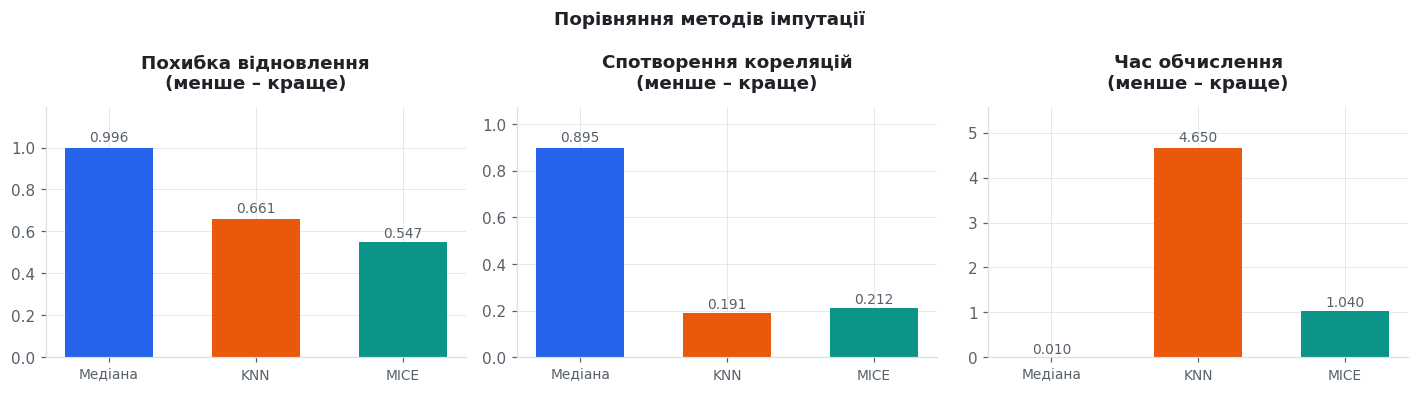

In [34]:
# --- Графік 1: порівняння за трьома критеріями ---
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
metrics = [("NRMSE", "Похибка відновлення\n(менше – краще)"),
           ("‖ΔC‖_F", "Спотворення кореляцій\n(менше – краще)"),
           ("Час, с", "Час обчислення\n(менше – краще)")]

for ax, (metric, title) in zip(axes, metrics):
    vals = imp_results[metric].values
    bars = ax.bar(range(len(imp_results)), vals, color=PALETTE[:len(imp_results)], width=.6)
    ax.set_xticks(range(len(imp_results)))
    ax.set_xticklabels(["Медіана", "KNN", "MICE"], fontsize=9)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, v * 1.02, f"{v:.3f}",
                ha="center", va="bottom", fontsize=9, color=MUTED)
    ax.set_ylim(0, max(vals) * 1.2)
    style_axes(ax, title=title, ylabel="")

fig.suptitle("Порівняння методів імпутації", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


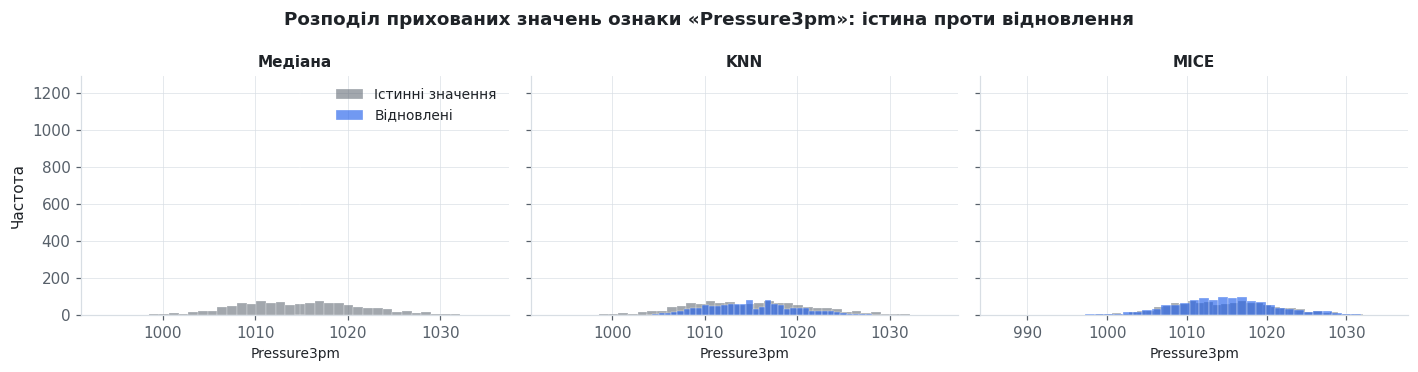

In [35]:
# --- Графік 2: що імпутація робить із розподілом ознаки ---
# Беремо ознаку з найбільшою кількістю прихованих значень
demo_col = NUM_FEATURES[int(np.argmax(mask_matrix.sum(axis=0)))]
j = NUM_FEATURES.index(demo_col)
m = mask_matrix[:, j]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, (data, name) in zip(axes, [(X_median, "Медіана"), (X_knn, "KNN"), (X_mice, "MICE")]):
    # Істинні значення прихованих клітинок
    ax.hist(ground_truth[demo_col].values[m], bins=40, alpha=.55,
            color=MUTED, label="Істинні значення", edgecolor="white", linewidth=.3)
    # Відновлені значення
    ax.hist(data[demo_col].values[m], bins=40, alpha=.65,
            color=PALETTE[0], label="Відновлені", edgecolor="white", linewidth=.3)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel(demo_col, fontsize=9)
axes[0].set_ylabel("Частота")
axes[0].legend(fontsize=9)

fig.suptitle(f"Розподіл прихованих значень ознаки «{demo_col}»: істина проти відновлення",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


### Комірка 3.5 – вибір методу та фінальна імпутація

Застосовуємо обраний метод до всіх вибірок (`fit` – лише на навчальній).

Додатково створюємо **бінарні ознаки-прапорці** наявності пропуску для ознак
із механізмом MNAR: сам факт відсутності вимірювання є інформативним, і після
імпутації ця інформація була б утрачена.

In [36]:
# --- Фінальна стратегія імпутації ---
# Ознаки з механізмом MNAR: пропуск несе інформацію про оснащення станції
MNAR_COLS = ["Sunshine", "Evaporation", "Cloud9am", "Cloud3pm"]

def add_missing_flags(frame):
    """Додає бінарні ознаки-прапорці наявності пропуску для MNAR-ознак."""
    out = frame.copy()
    for c in MNAR_COLS:
        out[f"{c}_missing"] = frame[c].isna().astype(int)
    return out

FLAG_FEATURES = [f"{c}_missing" for c in MNAR_COLS]

# Прапорці створюємо ДО імпутації – після неї інформація про пропуск зникне
df_train = add_missing_flags(df_train)
df_valid = add_missing_flags(df_valid)
df_test  = add_missing_flags(df_test)

print(f"Створено {len(FLAG_FEATURES)} ознак-прапорців: {', '.join(FLAG_FEATURES)}")
print("\nЧастка пропусків у навчальній вибірці за цими ознаками:")
for c, f in zip(MNAR_COLS, FLAG_FEATURES):
    print(f"  {c:<12} -> {df_train[f].mean() * 100:5.2f} %")

# Для категоріальних ознак перевіряємо моду
print("\nМоди категоріальних ознак (навчальна вибірка):")
for c in CAT_FEATURES:
    print(f"  {c:<14} -> {df_train[c].mode()[0]}")


Створено 4 ознак-прапорців: Sunshine_missing, Evaporation_missing, Cloud9am_missing, Cloud3pm_missing

Частка пропусків у навчальній вибірці за цими ознаками:
  Sunshine     -> 42.90 %
  Evaporation  -> 39.21 %
  Cloud9am     -> 36.45 %
  Cloud3pm     -> 37.67 %

Моди категоріальних ознак (навчальна вибірка):
  Location       -> Canberra
  WindGustDir    -> W
  WindDir9am     -> N
  WindDir3pm     -> SE
  RainToday      -> No


## 3.2. Кодування категоріальних ознак

### Комірка 3.6 – стратегія кодування

Метод кодування обираємо за потужністю множини значень ознаки:

* **висока кардинальність** → Target або Frequency Encoding (One-Hot створив би забагато розріджених стовпців);
* **помірна кардинальність без порядку** → One-Hot Encoding;
* **бінарна ознака** → Ordinal Encoding.

**Target Encoding** замінює категорію середнім значенням цілі в ній. Прямолінійна
реалізація спричиняє витік цілі, тому застосовуємо два захисні механізми.

**1. Згладжування (shrinkage)** – рідкісні категорії підтягуємо до глобального середнього:

$$\text{TE}(c) = \frac{n_c \cdot \bar{y}_c + m \cdot \bar{y}}{n_c + m}$$

де $n_c$ – кількість спостережень категорії, $\bar{y}_c$ – середнє цілі в категорії,
$\bar{y}$ – глобальне середнє, $m$ – параметр згладжування.

**2. Крос-фітинг (out-of-fold)** – для кожного рядка навчальної вибірки код обчислюється
на інших фолдах, тож власна мітка рядка у власний код не потрапляє.

In [37]:
# --- Власна реалізація Target Encoding зі згладжуванням і крос-фітингом ---
class SmoothedTargetEncoder:
    """Target Encoding із байєсівським згладжуванням та крос-фітингом.

    Формула згладжування:
        TE(c) = (n_c * mean_c + m * global_mean) / (n_c + m)

    Параметр m керує силою стягування: що він більший, то сильніше рідкісні
    категорії підтягуються до глобального середнього.
    """

    def __init__(self, smoothing=20, n_splits=5, random_state=RANDOM_STATE):
        self.smoothing = smoothing
        self.n_splits = n_splits
        self.random_state = random_state

    def fit(self, X, y):
        """Запам'ятовує коди категорій на ПОВНІЙ навчальній вибірці.

        Ці коди застосовуються до валідації й тесту (там витоку немає,
        бо їхні мітки у навчанні не брали участі).
        """
        self.global_mean_ = y.mean()           # базова частота позитивного класу
        # Для кожної категорії потрібні дві величини: скільки спостережень (count)
        # і яка в них частка позитивного класу (mean).
        stats_ = y.groupby(X).agg(["count", "mean"])
        # Формула згладжування – зважене середнє між власним середнім категорії
        # та глобальним. Вага власного середнього – n_c, глобального – m.
        # Якщо n_c >> m, код майже дорівнює mean_c; якщо n_c мале – тягнеться
        # до глобального середнього, що й захищає від шуму рідкісних категорій.
        self.mapping_ = ((stats_["count"] * stats_["mean"]
                          + self.smoothing * self.global_mean_)
                         / (stats_["count"] + self.smoothing))
        return self

    def transform(self, X):
        """Застосовує збережені коди; невідомі категорії -> глобальне середнє."""
        return X.map(self.mapping_).fillna(self.global_mean_).values

    def fit_transform_oof(self, X, y):
        """Коди для НАВЧАЛЬНОЇ вибірки, обчислені out-of-fold (без витоку).

        Для кожного фолду код рахується на решті фолдів, тож мітка самого
        рядка у його власний код не потрапляє.
        """
        out = np.full(len(X), np.nan)      # сюди складаємо коди по одному фолду
        kf = KFold(n_splits=self.n_splits, shuffle=True, random_state=self.random_state)
        for tr_idx, va_idx in kf.split(X):
            # Ключовий момент: статистики рахуємо на tr_idx, а ЗАСТОСОВУЄМО до va_idx.
            # Отже, мітка рядка не бере участі в обчисленні його власного коду.
            gm = y.iloc[tr_idx].mean()
            st = y.iloc[tr_idx].groupby(X.iloc[tr_idx]).agg(["count", "mean"])
            mp = ((st["count"] * st["mean"] + self.smoothing * gm)
                  / (st["count"] + self.smoothing))
            # fillna(gm): категорія могла не трапитися в цьому фолді – тоді
            # підставляємо середнє цього ж фолду, а не глобальне.
            out[va_idx] = X.iloc[va_idx].map(mp).fillna(gm).values
        self.fit(X, y)          # зберігаємо повні коди для valid/test
        return out

print("Клас SmoothedTargetEncoder визначено.")


Клас SmoothedTargetEncoder визначено.


In [38]:
# --- Застосування Target Encoding до ознаки Location ---
y_train_bin = (df_train[TARGET] == "Yes").astype(int)
y_valid_bin = (df_valid[TARGET] == "Yes").astype(int)
y_test_bin  = (df_test[TARGET] == "Yes").astype(int)

HIGH_CARD_COL = "Location"

# smoothing=20 означає: категорія починає "довіряти" власному середньому
# приблизно з 20 спостережень. У нас на кожну станцію їх тисячі, тож
# згладжування впливає слабко – але код лишається коректним і для рідкісних категорій.
te = SmoothedTargetEncoder(smoothing=20, n_splits=5)

# Для НАВЧАЛЬНОЇ вибірки – out-of-fold коди (захист від витоку);
# для валідації й тесту – звичайний transform: їхні мітки у навчанні не брали участі.
loc_te_train = te.fit_transform_oof(df_train[HIGH_CARD_COL], y_train_bin)
loc_te_valid = te.transform(df_valid[HIGH_CARD_COL])
loc_te_test  = te.transform(df_test[HIGH_CARD_COL])

# Демонстрація роботи згладжування
demo = pd.DataFrame({
    "Станція": te.mapping_.index,
    "Спостережень": y_train_bin.groupby(df_train[HIGH_CARD_COL]).count().values,
    "Частка дощів (сира)": y_train_bin.groupby(df_train[HIGH_CARD_COL]).mean().round(4).values,
    "Target Encoding (згладжено)": te.mapping_.round(4).values,
})
demo["Зсув до середнього"] = (demo["Target Encoding (згладжено)"]
                              - demo["Частка дощів (сира)"]).round(5)
demo = demo.sort_values("Частка дощів (сира)", ascending=False)

print(f"Глобальна частка дощів у навчальній вибірці: {te.global_mean_:.4f}\n")
print("Станції з найвищою та найнижчою ймовірністю дощу:")
display(pd.concat([demo.head(5), demo.tail(5)]).reset_index(drop=True))

print(f"Розкид кодів: {te.mapping_.min():.3f} … {te.mapping_.max():.3f}")


Глобальна частка дощів у навчальній вибірці: 0.2231

Станції з найвищою та найнижчою ймовірністю дощу:


,Станція,Спостережень,Частка дощів (сира),Target Encoding (згладжено),Зсув до середнього
0,Portland,2457,0.3651,0.3639,-0.0012
1,Walpole,2296,0.3293,0.3284,-0.0009
2,Dartmoor,2403,0.3150,0.3143,-0.0007
3,Cairns,2494,0.3132,0.3124,-0.0008
4,MountGambier,2498,0.3002,0.2996,-0.0006
5,Cobar,2461,0.1239,0.1247,0.0008
6,Mildura,2465,0.1095,0.1104,0.0009
7,AliceSprings,2498,0.0789,0.0800,0.0011
8,Woomera,2458,0.0655,0.0668,0.0013
9,Uluru,988,0.0607,0.0640,0.0033


Розкид кодів: 0.064 … 0.364


In [39]:
# --- Frequency Encoding: кодування частотою появи категорії ---
# Застосовуємо як альтернативу Target Encoding. Перевага – не використовує
# цільову змінну взагалі, тому витік цілі неможливий за побудовою.
freq_map = df_train[HIGH_CARD_COL].value_counts(normalize=True)

loc_freq_train = df_train[HIGH_CARD_COL].map(freq_map).fillna(0).values
loc_freq_valid = df_valid[HIGH_CARD_COL].map(freq_map).fillna(0).values
loc_freq_test  = df_test[HIGH_CARD_COL].map(freq_map).fillna(0).values

print("Frequency Encoding – частка спостережень кожної станції:")
print(f"  мінімум: {freq_map.min():.4f}  максимум: {freq_map.max():.4f}")
print(f"\nПорівняння двох підходів до кодування Location:")
cmp_enc = pd.DataFrame({
    "Метод": ["Target Encoding", "Frequency Encoding"],
    "Використовує ціль": ["так", "ні"],
    "Ризик витоку": ["є (знято крос-фітингом)", "немає"],
    "Прогностична сила": ["висока", "низька"],
    "Стовпців": [1, 1],
})
display(cmp_enc)


Frequency Encoding – частка спостережень кожної станції:
  мінімум: 0.0085  максимум: 0.0248

Порівняння двох підходів до кодування Location:


,Метод,Використовує ціль,Ризик витоку,Прогностична сила,Стовпців
0,Target Encoding,так,є (знято крос-фітингом),висока,1
1,Frequency Encoding,ні,немає,низька,1


In [40]:
# --- One-Hot Encoding для напрямків вітру та Ordinal для бінарної ознаки ---
ONEHOT_COLS = ["WindGustDir", "WindDir9am", "WindDir3pm"]
ORDINAL_COLS = ["RainToday"]

# handle_unknown="ignore" – якщо у валідації трапиться небачена категорія,
# усі її стовпці будуть нулями замість помилки.
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)
ohe.fit(df_train[ONEHOT_COLS].fillna("Unknown"))

ohe_names = ohe.get_feature_names_out(ONEHOT_COLS).tolist()
print(f"One-Hot Encoding: {len(ONEHOT_COLS)} ознаки -> {len(ohe_names)} бінарних стовпців")

# Ordinal для RainToday: No -> 0, Yes -> 1
ord_enc = OrdinalEncoder(categories=[["No", "Yes"]],
                         handle_unknown="use_encoded_value", unknown_value=-1)
ord_enc.fit(df_train[ORDINAL_COLS].fillna("No"))
print(f"Ordinal Encoding: RainToday -> {{No: 0, Yes: 1}}")

print(f"\nРазом після кодування категоріальних ознак: "
      f"1 (Location TE) + 1 (Location Freq) + {len(ohe_names)} (One-Hot) "
      f"+ {len(ORDINAL_COLS)} (Ordinal) = {2 + len(ohe_names) + len(ORDINAL_COLS)} стовпців")


One-Hot Encoding: 3 ознаки -> 51 бінарних стовпців
Ordinal Encoding: RainToday -> {No: 0, Yes: 1}

Разом після кодування категоріальних ознак: 1 (Location TE) + 1 (Location Freq) + 51 (One-Hot) + 1 (Ordinal) = 54 стовпців


## 3.3. Нормалізація та геометричні перетворення

### Комірка 3.7 – вибір методу масштабування

**RobustScaler** центрує за медіаною й масштабує за міжквартильним розмахом:

$$x' = \frac{x - \text{Me}}{Q_3 - Q_1}$$

На відміну від `StandardScaler`, стійкий до викидів, бо медіана та IQR від них не залежать.

**PowerTransformer** застосовує степеневе перетворення, підбираючи параметр λ методом
максимальної правдоподібності так, щоб результат був якомога ближчим до нормального розподілу.

Доступні дві функції:

* **Box-Cox** – вимагає **строго додатних** значень;
* **Yeo-Johnson** – працює з нулями й від'ємними значеннями.

Ознака `Rainfall` містить нулі (дні без опадів), `MinTemp` – від'ємні значення, тому
Box-Cox незастосовний і обираємо **Yeo-Johnson**. Перевіримо це програмно.

In [41]:
# --- Перевірка застосовності Box-Cox ---
print("Перевірка умови Box-Cox (усі значення строго додатні):\n")
box_cox_ok = []
for c in NUM_FEATURES:
    mn = df_train[c].min()
    n_zero = (df_train[c] == 0).sum()
    ok = mn > 0
    box_cox_ok.append(ok)
    if not ok:
        print(f"  {c:<16} мінімум = {mn:>8.2f}, нулів = {n_zero:>6,}"
              .replace(",", " ") + "  -> Box-Cox НЕЗАСТОСОВНИЙ")

print(f"\nПридатних для Box-Cox ознак: {sum(box_cox_ok)} із {len(NUM_FEATURES)}")

# Практична демонстрація помилки
try:
    PowerTransformer(method="box-cox").fit(df_train[["Rainfall"]].dropna())
except ValueError as e:
    print(f"\nСпроба застосувати Box-Cox до Rainfall:\n  ValueError: {e}")


Перевірка умови Box-Cox (усі значення строго додатні):

  MinTemp          мінімум =    -8.50  нулів =    134  -> Box-Cox НЕЗАСТОСОВНИЙ
  MaxTemp          мінімум =    -4.10  нулів =     13  -> Box-Cox НЕЗАСТОСОВНИЙ
  Rainfall         мінімум =     0.00  нулів = 73 859  -> Box-Cox НЕЗАСТОСОВНИЙ
  Evaporation      мінімум =     0.00  нулів =    212  -> Box-Cox НЕЗАСТОСОВНИЙ
  Sunshine         мінімум =     0.00  нулів =  2 016  -> Box-Cox НЕЗАСТОСОВНИЙ
  WindSpeed9am     мінімум =     0.00  нулів =  7 170  -> Box-Cox НЕЗАСТОСОВНИЙ
  WindSpeed3pm     мінімум =     0.00  нулів =    988  -> Box-Cox НЕЗАСТОСОВНИЙ
  Humidity9am      мінімум =     0.00  нулів =      1  -> Box-Cox НЕЗАСТОСОВНИЙ
  Humidity3pm      мінімум =     0.00  нулів =      4  -> Box-Cox НЕЗАСТОСОВНИЙ
  Cloud9am         мінімум =     0.00  нулів =  7 551  -> Box-Cox НЕЗАСТОСОВНИЙ
  Cloud3pm         мінімум =     0.00  нулів =  4 534  -> Box-Cox НЕЗАСТОСОВНИЙ
  Temp9am          мінімум =    -6.20  нулів =     32  -> Box-Co

In [42]:
# --- Порівняння RobustScaler та PowerTransformer (Yeo-Johnson) ---
# fit ЛИШЕ на навчальній вибірці; попередньо заповнюємо пропуски медіаною train
# Медіану беремо з НАВЧАЛЬНОЇ вибірки – це тимчасове заповнення лише для
# того, щоб коректно порівняти два способи масштабування між собою.
median_fill = df_train[NUM_FEATURES].median()
Xtr_num = df_train[NUM_FEATURES].fillna(median_fill)

t0 = time.time()
# RobustScaler: (x - медіана) / IQR. Лінійне перетворення, тому форма
# розподілу не змінюється – це й перевіримо нижче за коефіцієнтом асиметрії.
robust = RobustScaler().fit(Xtr_num)
Xtr_robust = pd.DataFrame(robust.transform(Xtr_num), columns=NUM_FEATURES)
t_robust = time.time() - t0

t0 = time.time()
# standardize=True додає StandardScaler ПІСЛЯ степеневого перетворення,
# тож на виході маємо нульове середнє й одиничну дисперсію.
power = PowerTransformer(method="yeo-johnson", standardize=True).fit(Xtr_num)
Xtr_power = pd.DataFrame(power.transform(Xtr_num), columns=NUM_FEATURES)
t_power = time.time() - t0

# Порівняння асиметрії до і після перетворень
scale_cmp = pd.DataFrame({
    "Ознака": NUM_FEATURES,
    "λ (Yeo-Johnson)": power.lambdas_.round(3),
    "Асиметрія до": Xtr_num.skew().round(3).values,
    "Після RobustScaler": Xtr_robust.skew().round(3).values,
    "Після Yeo-Johnson": Xtr_power.skew().round(3).values,
})
scale_cmp["Зменшення |skew|"] = (scale_cmp["Асиметрія до"].abs()
                                 - scale_cmp["Після Yeo-Johnson"].abs()).round(3)
display(scale_cmp.sort_values("Зменшення |skew|", ascending=False).reset_index(drop=True))

print(f"Середня |асиметрія| до перетворення:        {Xtr_num.skew().abs().mean():.3f}")
print(f"Після RobustScaler:                        {Xtr_robust.skew().abs().mean():.3f}  "
      f"(час {t_robust:.2f} с)")
print(f"Після PowerTransformer (Yeo-Johnson):      {Xtr_power.skew().abs().mean():.3f}  "
      f"(час {t_power:.2f} с)")


,Ознака,λ (Yeo-Johnson),Асиметрія до,Після RobustScaler,Після Yeo-Johnson,Зменшення |skew|
0,Rainfall,-1.679,10.146,10.146,1.017,9.129
1,Evaporation,0.149,4.390,4.390,0.046,4.344
2,WindGustSpeed,0.242,0.920,0.920,0.014,0.906
3,Sunshine,1.674,-1.022,-1.022,-0.207,0.815
4,WindSpeed9am,0.582,0.765,0.765,-0.059,0.706
5,WindSpeed3pm,0.620,0.617,0.617,0.019,0.598
6,Humidity9am,1.486,-0.493,-0.493,-0.111,0.382
7,Cloud3pm,1.344,-0.545,-0.545,-0.256,0.289
8,Cloud9am,1.272,-0.529,-0.529,-0.314,0.215
9,Temp3pm,0.812,0.258,0.258,0.057,0.201


Середня |асиметрія| до перетворення:        1.262
Після RobustScaler:                        1.262  (час 0.07 с)
Після PowerTransformer (Yeo-Johnson):      0.144  (час 0.77 с)


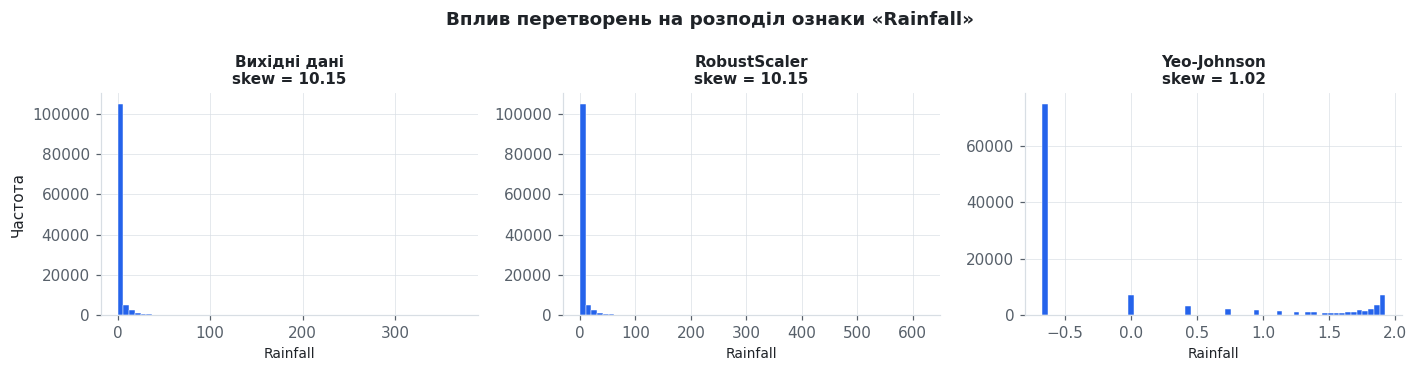

In [43]:
# --- Візуалізація ефекту перетворень на найасиметричнішій ознаці ---
worst = scale_cmp.loc[scale_cmp["Асиметрія до"].abs().idxmax(), "Ознака"]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
datasets = [(Xtr_num[worst], f"Вихідні дані\nskew = {Xtr_num[worst].skew():.2f}"),
            (Xtr_robust[worst], f"RobustScaler\nskew = {Xtr_robust[worst].skew():.2f}"),
            (Xtr_power[worst], f"Yeo-Johnson\nskew = {Xtr_power[worst].skew():.2f}")]

for ax, (data, title) in zip(axes, datasets):
    ax.hist(data, bins=60, color=PALETTE[0], edgecolor="white", linewidth=.3)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(worst, fontsize=9)
axes[0].set_ylabel("Частота")

fig.suptitle(f"Вплив перетворень на розподіл ознаки «{worst}»",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


### Комірка 3.8 – збірка єдиного конвеєра обробки

Усі кроки об'єднуємо у функцію, яка застосовується до кожної вибірки окремо.
Параметри перетворювачів беруться **лише з навчальної вибірки**.

In [44]:
# --- Єдиний конвеєр обробки ---
# Навчаємо перетворювачі ОДИН раз на навчальній вибірці
imputer_final = IterativeImputer(max_iter=10, random_state=RANDOM_STATE)
imputer_final.fit(df_train[NUM_FEATURES])

power_final = PowerTransformer(method="yeo-johnson", standardize=True)
power_final.fit(imputer_final.transform(df_train[NUM_FEATURES]))

cat_modes = {c: df_train[c].mode()[0] for c in CAT_FEATURES}

def build_matrix(frame, loc_te, loc_freq):
    """Перетворює сирий DataFrame на числову матрицю ознак.

    Порядок операцій:
      1) імпутація числових ознак (MICE, навчений на train);
      2) степеневе перетворення Yeo-Johnson;
      3) приєднання ознак-прапорців пропусків;
      4) приєднання закодованих категоріальних ознак.
    """
    # 1-2. Числові ознаки
    # transform (а не fit_transform!) – параметри вже вивчено на train.
    # Саме це правило відрізняє коректний конвеєр від конвеєра з витоком.
    num = imputer_final.transform(frame[NUM_FEATURES])
    num = power_final.transform(num)
    # index=frame.index зберігає вихідні індекси рядків – вони знадобляться
    # далі, щоб зіставити матрицю із сирим DataFrame при інженерії ознак.
    out = pd.DataFrame(num, columns=NUM_FEATURES, index=frame.index)

    # 3. Прапорці пропусків (інформація про механізм MNAR)
    for f in FLAG_FEATURES:
        out[f] = frame[f].values

    # 4. Категоріальні ознаки
    out["Location_te"] = loc_te        # Target Encoding
    out["Location_freq"] = loc_freq    # Frequency Encoding

    oh = ohe.transform(frame[ONEHOT_COLS].fillna("Unknown"))
    for i, name in enumerate(ohe_names):
        out[name] = oh[:, i]

    out["RainToday"] = ord_enc.transform(frame[ORDINAL_COLS].fillna("No")).ravel()
    return out

print("Формування матриць ознак …")
X_train = build_matrix(df_train, loc_te_train, loc_freq_train)
X_valid = build_matrix(df_valid, loc_te_valid, loc_freq_valid)
X_test  = build_matrix(df_test,  loc_te_test,  loc_freq_test)

y_train, y_valid, y_test = y_train_bin.values, y_valid_bin.values, y_test_bin.values

print(f"\nX_train: {X_train.shape[0]:,} × {X_train.shape[1]}".replace(",", " "))
print(f"X_valid: {X_valid.shape[0]:,} × {X_valid.shape[1]}".replace(",", " "))
print(f"X_test:  {X_test.shape[0]:,} × {X_test.shape[1]}".replace(",", " "))
print(f"\nПропусків у підсумкових матрицях: "
      f"{X_train.isna().sum().sum() + X_valid.isna().sum().sum() + X_test.isna().sum().sum()}")
print(f"\nСклад ознак: {len(NUM_FEATURES)} числових + {len(FLAG_FEATURES)} прапорців "
      f"+ 2 кодування Location + {len(ohe_names)} One-Hot + 1 Ordinal")


Формування матриць ознак …

X_train: 116 219 × 74
X_valid: 17 508 × 74
X_test:  8 466 × 74

Пропусків у підсумкових матрицях: 0

Склад ознак: 16 числових + 4 прапорців + 2 кодування Location + 51 One-Hot + 1 Ordinal


---
# Розділ 4. Аугментація та генерування даних

**Завдання методички:**

1. **Синтез нових спостережень** – SMOTE, ADASYN або додавання керованого гаусового шуму.
2. **Інженерія ознак** – нелінійні комбінації, поліноміальні ознаки, агрегації за категоріями.

> **Головне правило аугментації:** синтетичні дані створюються **виключно на навчальній
> вибірці**. Валідаційна й тестова вибірки залишаються недоторканими – інакше оцінка
> якості буде завищеною, бо модель перевірятиметься на даних, які сама ж і породила.

## 4.1. Методи аугментації

### Комірка 4.1 – теоретичні основи

**SMOTE** (Synthetic Minority Over-sampling Technique) створює нове спостереження
як точку на відрізку між наявним представником міноритарного класу та одним
із його $k$ найближчих сусідів того ж класу:

$$x_{\text{new}} = x_i + \lambda \cdot (x_{zi} - x_i), \qquad \lambda \sim U(0,1)$$

Це **лінійна інтерполяція у просторі ознак**, а не дублювання – тому модель отримує
нові точки, а не повтори старих.

**SMOTE-NC** (Nominal-Continuous) – версія для змішаних даних. Звичайний SMOTE
інтерполював би й категоріальні стовпці, даючи безглузді «напівкатегорії»
(наприклад, 0,5 між напрямками N та NE). SMOTE-NC натомість присвоює синтетичному
зразку **найчастішу категорію серед сусідів**.

**ADASYN** (Adaptive Synthetic Sampling) – адаптивна модифікація: генерує більше
зразків там, де міноритарний клас оточений мажоритарним, тобто поблизу складної
межі прийняття рішень.

**Гаусів шум** – найпростіший підхід: дублюємо зразки міноритарного класу й додаємо
збурення $\varepsilon \sim N(0, \alpha\sigma)$. Згідно з лекційним матеріалом, додавання
шуму на вхід еквівалентне штрафуванню великих градієнтів функції, тобто працює
як регуляризатор.

In [45]:
# --- Параметри експерименту з аугментацією ---
# Для прискорення беремо підвибірку навчальних даних: алгоритми SMOTE/ADASYN
# мають складність O(n^2) за побудовою графа найближчих сусідів.
AUG_SAMPLE_N = 40000

aug_idx = (pd.Series(range(len(X_train)))
           .sample(min(AUG_SAMPLE_N, len(X_train)), random_state=RANDOM_STATE)
           .values)

X_aug_base = X_train.iloc[aug_idx].reset_index(drop=True)
y_aug_base = y_train[aug_idx]

print(f"Навчальна підвибірка для аугментації: {len(X_aug_base):,}".replace(",", " "))
print(f"  клас 0 (без дощу): {(y_aug_base == 0).sum():,}".replace(",", " "),
      f"({(y_aug_base == 0).mean() * 100:.2f} %)")
print(f"  клас 1 (дощ):      {(y_aug_base == 1).sum():,}".replace(",", " "),
      f"({(y_aug_base == 1).mean() * 100:.2f} %)")
print(f"\nВалідаційна вибірка (НЕ аугментується): {len(X_valid):,}".replace(",", " "))


Навчальна підвибірка для аугментації: 40 000
  клас 0 (без дощу): 31 034 (77.59 %)
  клас 1 (дощ):      8 966 (22.41 %)

Валідаційна вибірка (НЕ аугментується): 17 508


In [46]:
# --- Застосування чотирьох методів аугментації ---
augmented = {}   # назва -> (X, y, час)

# ---------- 0. Базовий варіант без аугментації ----------
augmented["Без аугментації"] = (X_aug_base, y_aug_base, 0.0)

# ---------- 1. SMOTE ----------
t0 = time.time()
# sampling_strategy=1.0 – доводимо міноритарний клас до рівності з мажоритарним.
# k_neighbors=5 – скільки найближчих сусідів того ж класу розглядати як
# кандидатів для інтерполяції; менше k дає щільніші, але менш різноманітні зразки.
sm = SMOTE(sampling_strategy=1.0, k_neighbors=5, random_state=RANDOM_STATE)
# fit_resample повертає НОВУ вибірку: спершу всі вихідні рядки, потім синтетичні
X_sm, y_sm = sm.fit_resample(X_aug_base, y_aug_base)
augmented["SMOTE"] = (X_sm, y_sm, time.time() - t0)
print(f"[1/4] SMOTE: {len(X_aug_base):,} -> {len(X_sm):,} рядків".replace(",", " "))

# ---------- 2. ADASYN ----------
t0 = time.time()
ada = ADASYN(sampling_strategy=1.0, n_neighbors=5, random_state=RANDOM_STATE)
X_ad, y_ad = ada.fit_resample(X_aug_base, y_aug_base)
augmented["ADASYN"] = (X_ad, y_ad, time.time() - t0)
print(f"[2/4] ADASYN: {len(X_aug_base):,} -> {len(X_ad):,} рядків".replace(",", " "))

# ---------- 3. Керований гаусів шум ----------
t0 = time.time()
NOISE_ALPHA = 0.05      # частка стандартного відхилення

minority = X_aug_base[y_aug_base == 1]
n_needed = (y_aug_base == 0).sum() - (y_aug_base == 1).sum()   # скільки добрати до балансу

rng_noise = np.random.default_rng(RANDOM_STATE)
# Вибір із поверненням: один і той самий реальний зразок може стати основою
# для кількох синтетичних – саме тому шум тут обов'язковий, інакше це були б
# прості дублікати, які нічого не додають.
dup_idx = rng_noise.integers(0, len(minority), n_needed)
synthetic = minority.iloc[dup_idx].reset_index(drop=True).copy()

# Шум додаємо ЛИШЕ до неперервних ознак: бінарні (One-Hot, прапорці) чіпати не можна
BINARY_COLS = [c for c in X_aug_base.columns
               if set(X_aug_base[c].unique()) <= {0.0, 1.0, 0, 1}]
CONTINUOUS_COLS = [c for c in X_aug_base.columns if c not in BINARY_COLS]

sigma = X_aug_base[CONTINUOUS_COLS].std()
# Шум масштабуємо на власне sigma кожної ознаки: збурення має бути пропорційним
# її природному розкиду, інакше для одних ознак воно буде мізерним, для інших –
# руйнівним. alpha = 0.05 означає "5 % стандартного відхилення".
noise = rng_noise.normal(0, 1, (len(synthetic), len(CONTINUOUS_COLS))) * (NOISE_ALPHA * sigma.values)
synthetic[CONTINUOUS_COLS] = synthetic[CONTINUOUS_COLS].values + noise

X_noise = pd.concat([X_aug_base, synthetic], ignore_index=True)
y_noise = np.concatenate([y_aug_base, np.ones(len(synthetic), dtype=int)])
augmented["Гаусів шум (α=0.05)"] = (X_noise, y_noise, time.time() - t0)
print(f"[3/4] Гаусів шум: {len(X_aug_base):,} -> {len(X_noise):,} рядків".replace(",", " "))
print(f"      бінарних ознак (шум не додається): {len(BINARY_COLS)}, "
      f"неперервних: {len(CONTINUOUS_COLS)}")

# ---------- 4. SMOTE-NC на СИРИХ даних зі справжніми категоріями ----------
# Демонструє коректну роботу зі змішаними типами, як вимагає лекційний матеріал.
t0 = time.time()
raw_cols = NUM_FEATURES + CAT_FEATURES
raw_sub = df_train.iloc[aug_idx][raw_cols].copy().reset_index(drop=True)
# SMOTE-NC не працює з пропусками – тимчасово заповнюємо
raw_sub[NUM_FEATURES] = raw_sub[NUM_FEATURES].fillna(df_train[NUM_FEATURES].median())
for c in CAT_FEATURES:
    raw_sub[c] = raw_sub[c].fillna(cat_modes[c]).astype(str)

# SMOTE-NC приймає ПОЗИЦІЇ категоріальних стовпців (цілі числа), а не їхні назви
cat_positions = [raw_sub.columns.get_loc(c) for c in CAT_FEATURES]
smnc = SMOTENC(categorical_features=cat_positions, sampling_strategy=1.0,
               k_neighbors=5, random_state=RANDOM_STATE)
X_smnc_raw, y_smnc = smnc.fit_resample(raw_sub, y_aug_base)
t_smnc = time.time() - t0
print(f"[4/4] SMOTE-NC: {len(raw_sub):,} -> {len(X_smnc_raw):,} рядків".replace(",", " "))

print("\nПеревірка коректності SMOTE-NC: синтетичні категорії залишилися валідними")
for c in CAT_FEATURES[:3]:
    orig = set(raw_sub[c].unique())
    new = set(X_smnc_raw[c].unique())
    print(f"  {c:<14} нових (невалідних) значень: {len(new - orig)}")


[1/4] SMOTE: 40 000 -> 62 068 рядків
[2/4] ADASYN: 40 000 -> 62 543 рядків
[3/4] Гаусів шум: 40 000 -> 62 068 рядків
      бінарних ознак (шум не додається): 56, неперервних: 18
[4/4] SMOTE-NC: 40 000 -> 62 068 рядків

Перевірка коректності SMOTE-NC: синтетичні категорії залишилися валідними
  Location       нових (невалідних) значень: 0
  WindGustDir    нових (невалідних) значень: 0
  WindDir9am     нових (невалідних) значень: 0


### Комірка 4.2 – оцінка якості синтетичних даних

Згенерувати дані мало – треба перевірити, що вони **статистично правдоподібні**.
Застосовуємо два критерії з лекційного матеріалу:

1. **Критерій Колмогорова-Смирнова** – чи збігаються розподіли окремих ознак
   у реальних та синтетичних зразках міноритарного класу;
2. **Норма Фробеніуса різниці кореляційних матриць** $\lVert C_{\text{real}} - C_{\text{syn}} \rVert_F$ –
   чи збереглися **зв'язки між ознаками**. Саме цей критерій згадувався в лекції як
   ключовий для табличних даних: синтетичні зразки не повинні створювати фізично
   неможливих комбінацій.

In [47]:
# --- Оцінка статистичної якості синтетичних даних ---
X_real_minority = X_aug_base[y_aug_base == 1]
C_real = X_real_minority[CONTINUOUS_COLS].corr().values

quality_rows = []
for name, (Xa, ya, t) in augmented.items():
    if name == "Без аугментації":
        continue
    # Синтетичні зразки – це рядки, додані ПІСЛЯ вихідної вибірки
    synth = Xa.iloc[len(X_aug_base):]
    if len(synth) == 0:
        continue

    # KS-статистика по кожній неперервній ознаці
    ks = [stats.ks_2samp(X_real_minority[c], synth[c]).statistic for c in CONTINUOUS_COLS]

    # Норма Фробеніуса різниці кореляційних матриць
    C_syn = synth[CONTINUOUS_COLS].corr().values
    frob = np.linalg.norm(C_real - np.nan_to_num(C_syn), ord="fro")

    quality_rows.append({
        "Метод": name,
        "Синтетичних зразків": len(synth),
        "KS (середня)": round(np.mean(ks), 4),
        "KS (максимум)": round(np.max(ks), 4),
        "‖C_real − C_syn‖_F": round(frob, 4),
        "Час, с": round(t, 2),
    })

quality = pd.DataFrame(quality_rows)
display(quality)


,Метод,Синтетичних зразків,KS (середня),KS (максимум),‖C_real − C_syn‖_F,"Час, с"
0,SMOTE,22068,0.0429,0.0966,0.4593,0.70
1,ADASYN,22543,0.0937,0.1821,1.0808,3.38
2,Гаусів шум (α=0.05),22068,0.0417,0.1816,0.2510,0.07


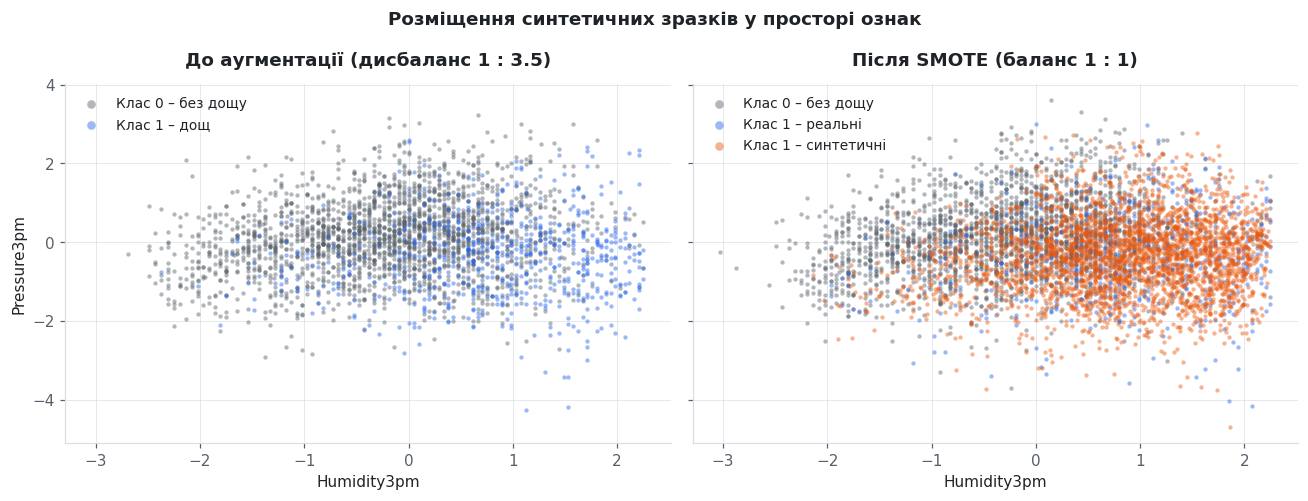

In [48]:
# --- Візуалізація: де саме SMOTE розміщує синтетичні точки ---
# Проєкція на дві найінформативніші ознаки
viz_cols = ["Humidity3pm", "Pressure3pm"]
X_sm_v, y_sm_v = augmented["SMOTE"][0], augmented["SMOTE"][1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True, sharey=True)
PLOT_N = 3000

# Ліворуч: вихідні дані
rs = np.random.default_rng(RANDOM_STATE)
sel = rs.choice(len(X_aug_base), min(PLOT_N, len(X_aug_base)), replace=False)
for cls, color, label in [(0, MUTED, "Клас 0 – без дощу"), (1, PALETTE[0], "Клас 1 – дощ")]:
    m = y_aug_base[sel] == cls
    axes[0].scatter(X_aug_base[viz_cols[0]].values[sel][m],
                    X_aug_base[viz_cols[1]].values[sel][m],
                    s=8, alpha=.45, color=color, label=label, linewidths=0)
axes[0].legend(fontsize=9, markerscale=2)
style_axes(axes[0], title=f"До аугментації (дисбаланс 1 : {(y_aug_base == 0).sum() / (y_aug_base == 1).sum():.1f})",
           xlabel=viz_cols[0], ylabel=viz_cols[1])

# Праворуч: після SMOTE – окремо позначаємо синтетичні точки
n_orig = len(X_aug_base)
sel2 = rs.choice(n_orig, min(PLOT_N, n_orig), replace=False)
synth_idx = np.arange(n_orig, len(X_sm_v))
sel3 = rs.choice(synth_idx, min(PLOT_N, len(synth_idx)), replace=False)

for cls, color, label in [(0, MUTED, "Клас 0 – без дощу"), (1, PALETTE[0], "Клас 1 – реальні")]:
    m = y_sm_v[sel2] == cls
    axes[1].scatter(X_sm_v[viz_cols[0]].values[sel2][m],
                    X_sm_v[viz_cols[1]].values[sel2][m],
                    s=8, alpha=.45, color=color, label=label, linewidths=0)
axes[1].scatter(X_sm_v[viz_cols[0]].values[sel3], X_sm_v[viz_cols[1]].values[sel3],
                s=8, alpha=.45, color=PALETTE[1], label="Клас 1 – синтетичні", linewidths=0)
axes[1].legend(fontsize=9, markerscale=2)
style_axes(axes[1], title="Після SMOTE (баланс 1 : 1)", xlabel=viz_cols[0], ylabel="")

fig.suptitle("Розміщення синтетичних зразків у просторі ознак", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


### Комірка 4.3 – перевірка практичної користі аугментації

Статистична правдоподібність ще не означає, що аугментація **допомагає моделі**.
Навчаємо однакову модель (`HistGradientBoostingClassifier`) на кожному варіанті
й оцінюємо на **незайманій валідаційній вибірці**.

**Метрики.** Через дисбаланс класів Accuracy непридатна (див. розділ 1). Використовуємо:

* **PR-AUC** (середня точність) – головна метрика для незбалансованих задач;
* **F1-міра** – гармонійне середнє точності й повноти;
* **Recall** – частка виявлених дощових днів;
* **Precision** – частка справджених прогнозів дощу;
* **ROC-AUC** – якість ранжування за різних порогів.

In [49]:
# --- Оцінка практичної користі кожного методу аугментації ---
def evaluate_model(X_tr, y_tr, X_va, y_va, name):
    """Навчає модель і повертає набір метрик на валідаційній вибірці."""
    t0 = time.time()
    # HistGradientBoosting обрано як "однакову для всіх" модель-арбітра: він
    # швидкий на сотнях тисяч рядків і не вимагає масштабування ознак, тож
    # різниця метрик пояснюватиметься саме аугментацією, а не налаштуванням моделі.
    model = HistGradientBoostingClassifier(
        max_iter=150, learning_rate=.1, max_depth=None,
        random_state=RANDOM_STATE,
    )
    model.fit(X_tr, y_tr)
    # [:, 1] – ймовірність ПОЗИТИВНОГО класу (стовпець 0 – ймовірність класу 0)
    proba = model.predict_proba(X_va)[:, 1]
    # Поріг 0.5 навмисно НЕ підбираємо: інакше ефект аугментації змішався б
    # з ефектом підбору порога, а це два різні способи боротьби з дисбалансом.
    pred = (proba >= .5).astype(int)
    return {
        "Варіант": name,
        "Рядків у навчанні": len(X_tr),
        "PR-AUC": round(average_precision_score(y_va, proba), 4),
        "ROC-AUC": round(roc_auc_score(y_va, proba), 4),
        "F1": round(f1_score(y_va, pred), 4),
        "Recall": round(recall_score(y_va, pred), 4),
        "Precision": round(precision_score(y_va, pred), 4),
        "Час навчання, с": round(time.time() - t0, 1),
    }

model_results = []
for name, (Xa, ya, _) in augmented.items():
    model_results.append(evaluate_model(Xa, ya, X_valid, y_valid, name))
    print(f"  {name:<24} готово")

# Додатково: вбудоване зважування класів як альтернатива аугментації
t0 = time.time()
# Кожному зразку міноритарного класу даємо вагу, що дорівнює співвідношенню
# класів: один реальний дощовий день "важить" стільки ж, скільки ~3.5 сухих.
# Це дає той самий ефект, що й оверсемплінг, але без створення нових рядків.
w = np.where(y_aug_base == 1,
             (y_aug_base == 0).sum() / (y_aug_base == 1).sum(), 1.0)
m_w = HistGradientBoostingClassifier(max_iter=150, random_state=RANDOM_STATE)
m_w.fit(X_aug_base, y_aug_base, sample_weight=w)
p_w = m_w.predict_proba(X_valid)[:, 1]
pred_w = (p_w >= .5).astype(int)
model_results.append({
    "Варіант": "Зважування класів",
    "Рядків у навчанні": len(X_aug_base),
    "PR-AUC": round(average_precision_score(y_valid, p_w), 4),
    "ROC-AUC": round(roc_auc_score(y_valid, p_w), 4),
    "F1": round(f1_score(y_valid, pred_w), 4),
    "Recall": round(recall_score(y_valid, pred_w), 4),
    "Precision": round(precision_score(y_valid, pred_w), 4),
    "Час навчання, с": round(time.time() - t0, 1),
})
print("  Зважування класів       готово\n")

aug_results = pd.DataFrame(model_results)
display(aug_results)


  Без аугментації          готово
  SMOTE                    готово
  ADASYN                   готово
  Гаусів шум (α=0.05)      готово
  Зважування класів       готово



,Варіант,Рядків у навчанні,PR-AUC,ROC-AUC,F1,Recall,Precision,"Час навчання, с"
0,Без аугментації,40000,0.7294,0.8731,0.6300,0.5539,0.7305,3.6
1,SMOTE,62068,0.7208,0.8689,0.6316,0.5929,0.6757,6.8
2,ADASYN,62543,0.7162,0.8670,0.6283,0.5938,0.6670,6.3
3,Гаусів шум (α=0.05),62068,0.7117,0.8651,0.6250,0.5852,0.6705,6.5
4,Зважування класів,40000,0.7264,0.8716,0.6433,0.7758,0.5494,3.0


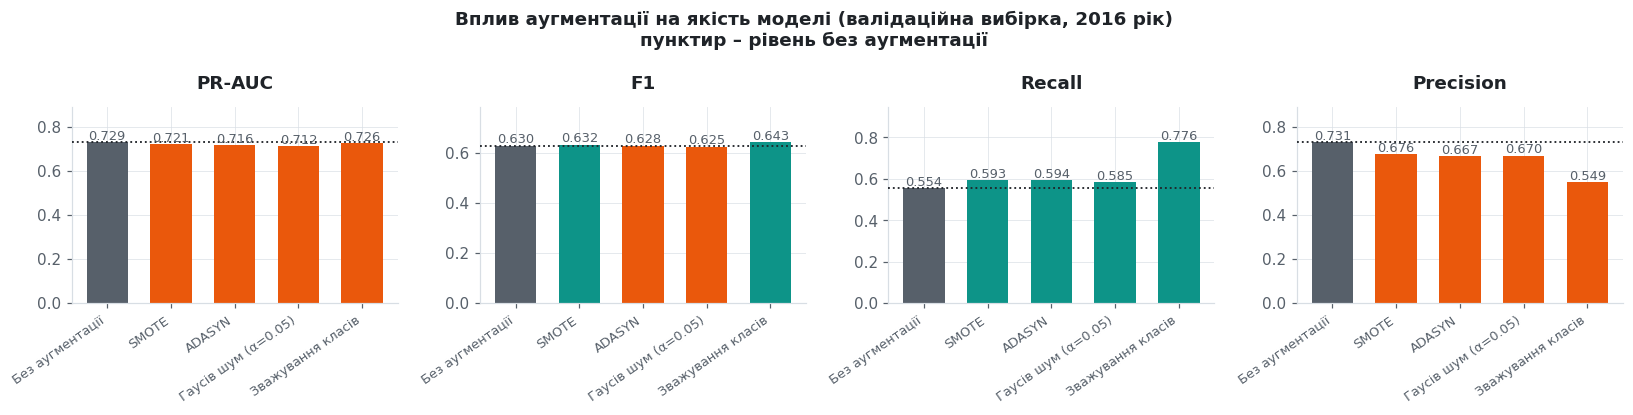

In [50]:
# --- Візуалізація впливу аугментації на метрики ---
plot_metrics = ["PR-AUC", "F1", "Recall", "Precision"]
labels = aug_results["Варіант"].tolist()
x = np.arange(len(labels))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharex=True)
baseline = aug_results.iloc[0]

for ax, metric in zip(axes, plot_metrics):
    vals = aug_results[metric].values
    # Колір кодує напрямок зміни відносно базового варіанта – це стан, не величина:
    # сірий – база, бірюзовий – покращення, жовтогарячий – погіршення.
    colors = [MUTED] + [PALETTE[2] if v >= baseline[metric] else PALETTE[1]
                        for v in vals[1:]]
    bars = ax.bar(x, vals, color=colors, width=.65)
    ax.axhline(baseline[metric], color=INK, linestyle=":", linewidth=1.2, zorder=3)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, v + .012, f"{v:.3f}",
                ha="center", fontsize=8.5, color=MUTED)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=35, ha="right", fontsize=8.5)
    ax.set_ylim(0, max(vals) * 1.22)
    style_axes(ax, title=metric, ylabel="")

fig.suptitle("Вплив аугментації на якість моделі (валідаційна вибірка, 2016 рік)\n"
             "пунктир – рівень без аугментації", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


In [51]:
# --- Зміни метрик відносно варіанта без аугментації ---
base = aug_results.iloc[0]
print("Зміни відносно варіанта без аугментації:\n")
print(f"{'Варіант':<24}{'ΔPR-AUC':>10}{'ΔRecall':>10}{'ΔPrecision':>12}{'ΔF1':>10}")
print("-" * 66)
for _, r in aug_results.iloc[1:].iterrows():
    print(f"{r['Варіант']:<24}"
          f"{r['PR-AUC'] - base['PR-AUC']:>+10.4f}"
          f"{r['Recall'] - base['Recall']:>+10.4f}"
          f"{r['Precision'] - base['Precision']:>+12.4f}"
          f"{r['F1'] - base['F1']:>+10.4f}")


Зміни відносно варіанта без аугментації:

Варіант                    ΔPR-AUC   ΔRecall  ΔPrecision       ΔF1
------------------------------------------------------------------
SMOTE                      -0.0086   +0.0390     -0.0548   +0.0016
ADASYN                     -0.0132   +0.0399     -0.0635   -0.0017
Гаусів шум (α=0.05)        -0.0177   +0.0313     -0.0600   -0.0050
Зважування класів          -0.0030   +0.2219     -0.1811   +0.0133


### Комірка 4.4 – аугментація за значного дисбалансу

Повторюємо експеримент на допоміжній цілі «сильні опади», де позитивний клас
значно рідкісніший, і зіставляємо приріст метрик із основним експериментом.

In [52]:
# --- Експеримент на допоміжній цілі з жорстким дисбалансом ---
heavy_tr = df_train["HeavyRainTomorrow"].notna().values
heavy_va = df_valid["HeavyRainTomorrow"].notna().values

Xh_tr = X_train[heavy_tr]
yh_tr = df_train.loc[heavy_tr, "HeavyRainTomorrow"].astype(int).values
Xh_va = X_valid[heavy_va]
yh_va = df_valid.loc[heavy_va, "HeavyRainTomorrow"].astype(int).values

# Підвибірка для швидкості
hs = (pd.Series(range(len(Xh_tr)))
      .sample(min(AUG_SAMPLE_N, len(Xh_tr)), random_state=RANDOM_STATE).values)
Xh_tr, yh_tr = Xh_tr.iloc[hs].reset_index(drop=True), yh_tr[hs]

print(f"Навчальна вибірка: {len(Xh_tr):,}".replace(",", " "),
      f"| позитивного класу: {yh_tr.mean() * 100:.2f} %",
      f"| дисбаланс 1 : {(1 - yh_tr.mean()) / yh_tr.mean():.0f}")

heavy_results = [evaluate_model(Xh_tr, yh_tr, Xh_va, yh_va, "Без аугментації")]

# Перевіряємо ДВІ міри вирівнювання, щоб порівняння з основним експериментом
# (де застосовувалося повне вирівнювання 1:1) було коректним.
for strategy, label in [(.3, "SMOTE (часткове, до 1:3.3)"),
                        (1.0, "SMOTE (повне, до 1:1)")]:
    sm_h = SMOTE(sampling_strategy=strategy, k_neighbors=5, random_state=RANDOM_STATE)
    Xh_sm, yh_sm = sm_h.fit_resample(Xh_tr, yh_tr)
    heavy_results.append(evaluate_model(Xh_sm, yh_sm, Xh_va, yh_va, label))

ad_h = ADASYN(sampling_strategy=.3, n_neighbors=5, random_state=RANDOM_STATE)
Xh_ad, yh_ad = ad_h.fit_resample(Xh_tr, yh_tr)
heavy_results.append(evaluate_model(Xh_ad, yh_ad, Xh_va, yh_va, "ADASYN (часткове, до 1:3.3)"))

heavy_df = pd.DataFrame(heavy_results)
display(heavy_df)

# --- Зіставлення двох режимів дисбалансу за ОДНАКОВОЇ міри вирівнювання (1:1) ---
ratio_heavy = (1 - yh_tr.mean()) / yh_tr.mean()
d_recall_heavy = heavy_df.loc[heavy_df["Варіант"] == "SMOTE (повне, до 1:1)", "Recall"].iloc[0]                  - heavy_df.iloc[0]["Recall"]
d_prauc_heavy = heavy_df.loc[heavy_df["Варіант"] == "SMOTE (повне, до 1:1)", "PR-AUC"].iloc[0]                 - heavy_df.iloc[0]["PR-AUC"]
d_recall_mod = aug_results.iloc[1]["Recall"] - aug_results.iloc[0]["Recall"]
d_prauc_mod = aug_results.iloc[1]["PR-AUC"] - aug_results.iloc[0]["PR-AUC"]

cmp_imb = pd.DataFrame({
    "Режим": [f"Помірний дисбаланс (1 : {n_no / n_yes:.1f})",
              f"Значний дисбаланс (1 : {ratio_heavy:.0f})"],
    "Ціль": ["RainTomorrow", "HeavyRainTomorrow"],
    "ΔRecall від SMOTE (1:1)": [round(d_recall_mod, 4), round(d_recall_heavy, 4)],
    "ΔPR-AUC від SMOTE (1:1)": [round(d_prauc_mod, 4), round(d_prauc_heavy, 4)],
})
display(cmp_imb)

print("Таблицю зміни метрик для обох режимів дисбалансу сформовано.")


Навчальна вибірка: 40 000 | позитивного класу: 2.02 % | дисбаланс 1 : 48


,Варіант,Рядків у навчанні,PR-AUC,ROC-AUC,F1,Recall,Precision,"Час навчання, с"
0,Без аугментації,40000,0.2508,0.9052,0.2123,0.1433,0.4091,1.4
1,"SMOTE (часткове, до 1:3.3)",50947,0.2680,0.9061,0.2441,0.1656,0.4643,5.5
2,"SMOTE (повне, до 1:1)",78380,0.2417,0.9004,0.2495,0.1847,0.3841,8.3
3,"ADASYN (часткове, до 1:3.3)",50802,0.2581,0.9054,0.2319,0.1529,0.4800,6.1


,Режим,Ціль,ΔRecall від SMOTE (1:1),ΔPR-AUC від SMOTE (1:1)
0,Помірний дисбаланс (1 : 3.5),RainTomorrow,0.0390,-0.0086
1,Значний дисбаланс (1 : 48),HeavyRainTomorrow,0.0414,-0.0091


Таблицю зміни метрик для обох режимів дисбалансу сформовано.


## 4.2. Інженерія ознак (Feature Engineering)

### Комірка 4.5 – створення змістовних ознак

Нові ознаки будуємо не навмання, а виходячи з **фізики атмосферних процесів**:

| Нова ознака | Формула | Фізичний зміст |
|---|---|---|
| `TempRange` | `MaxTemp − MinTemp` | добова амплітуда; мала амплітуда – ознака хмарності |
| `PressureDrop` | `Pressure3pm − Pressure9am` | падіння тиску – класичний провісник негоди |
| `HumidityChange` | `Humidity3pm − Humidity9am` | динаміка зволоження повітря |
| `CloudChange` | `Cloud3pm − Cloud9am` | наростання хмарності |
| `WindChange` | `WindSpeed3pm − WindSpeed9am` | посилення вітру |
| `HumidityPressure` | `Humidity3pm × (1010 − Pressure3pm)` | взаємодія: вологе повітря за низького тиску |
| `TempHumidityIdx` | `Temp3pm × Humidity3pm / 100` | наближення до точки роси |
| `SunshineRatio` | `Sunshine / (Evaporation + 1)` | співвідношення інсоляції та випаровування |

In [53]:
# --- Інженерія змістовних ознак ---
def engineer_features(frame, base_matrix):
    """Додає нові ознаки, похідні від вихідних метеопоказників.

    Працюємо з СИРИМИ значеннями (frame), бо фізичний зміст різниць
    втрачається після степеневого перетворення.
    """
    out = base_matrix.copy()
    f = frame

    # --- Різниці: динаміка показника протягом доби ---
    out["TempRange"] = (f["MaxTemp"] - f["MinTemp"]).values
    out["PressureDrop"] = (f["Pressure3pm"] - f["Pressure9am"]).values
    out["HumidityChange"] = (f["Humidity3pm"] - f["Humidity9am"]).values
    out["CloudChange"] = (f["Cloud3pm"] - f["Cloud9am"]).values
    out["WindChange"] = (f["WindSpeed3pm"] - f["WindSpeed9am"]).values
    out["TempChange"] = (f["Temp3pm"] - f["Temp9am"]).values

    # --- Нелінійні взаємодії ---
    # Вологе повітря за низького тиску – найсильніший провісник опадів
    out["HumidityPressure"] = (f["Humidity3pm"] * (1010 - f["Pressure3pm"])).values
    out["TempHumidityIdx"] = (f["Temp3pm"] * f["Humidity3pm"] / 100).values
    out["SunshineRatio"] = (f["Sunshine"] / (f["Evaporation"] + 1)).values
    out["WindGustRatio"] = (f["WindGustSpeed"] / (f["WindSpeed3pm"] + 1)).values

    # --- Сезонність: місяць як циклічна величина ---
    # Простий номер місяця хибний: грудень (12) і січень (1) опиняться "далеко",
    # хоча сезонно вони сусідні. Кодуємо через синус і косинус.
    month = f["Date"].dt.month.values
    # Ділимо на 12 (повний цикл) і беремо синус та косинус. Потрібні ОБИДВІ
    # функції: сам синус дав би однакове значення для різних місяців (напр.,
    # лютий і жовтень), і лише пара (sin, cos) задає точку на колі однозначно.
    out["month_sin"] = np.sin(2 * np.pi * month / 12)
    out["month_cos"] = np.cos(2 * np.pi * month / 12)

    # --- Оцінка аномальності з розділу 2 ---
    out["anomaly_score"] = f["anomaly_score"].values

    return out

ENGINEERED = ["TempRange", "PressureDrop", "HumidityChange", "CloudChange",
              "WindChange", "TempChange", "HumidityPressure", "TempHumidityIdx",
              "SunshineRatio", "WindGustRatio", "month_sin", "month_cos",
              "anomaly_score"]

X_train_fe = engineer_features(df_train, X_train)
X_valid_fe = engineer_features(df_valid, X_valid)
X_test_fe  = engineer_features(df_test,  X_test)

# Нові ознаки обчислені з сирих даних, тому можуть містити пропуски -> заповнюємо
fe_median = X_train_fe[ENGINEERED].median()
for X_ in (X_train_fe, X_valid_fe, X_test_fe):
    X_[ENGINEERED] = X_[ENGINEERED].fillna(fe_median)

print(f"Створено {len(ENGINEERED)} нових ознак")
print(f"Розмірність матриці: {X_train.shape[1]} -> {X_train_fe.shape[1]} ознак")


Створено 13 нових ознак
Розмірність матриці: 74 -> 87 ознак


### Комірка 4.6 – агрегації за категоріями

Створюємо ознаки-відхилення показника від кліматичної норми **своєї** метеостанції:
одне й те саме значення температури може бути звичайним для одного регіону
й аномальним для іншого.

Норму (середнє та стандартне відхилення по станції) обчислюємо лише на навчальній вибірці.

In [54]:
# --- Агрегації за станціями: відхилення від кліматичної норми ---
AGG_COLS = ["MaxTemp", "Humidity3pm", "Pressure3pm", "Rainfall"]

# Кліматичну норму рахуємо ЛИШЕ на навчальній вибірці
station_stats = df_train.groupby("Location")[AGG_COLS].agg(["mean", "std"])
station_stats.columns = [f"{c}_{s}" for c, s in station_stats.columns]
global_stats = df_train[AGG_COLS].agg(["mean", "std"])

def add_station_deviation(frame, matrix):
    """Додає z-відхилення показника від кліматичної норми станції."""
    out = matrix.copy()
    # join(on="Location") підтягує до кожного рядка статистики ЙОГО станції
    joined = frame[["Location"] + AGG_COLS].join(station_stats, on="Location")
    for c in AGG_COLS:
        # Станція могла не трапитися в навчальній вибірці – тоді беремо
        # загальну норму по всіх станціях замість NaN.
        mu = joined[f"{c}_mean"].fillna(global_stats.loc["mean", c])
        sd = joined[f"{c}_std"].fillna(global_stats.loc["std", c]).replace(0, 1)
        # Скільки стандартних відхилень від норми СВОЄЇ станції
        out[f"{c}_dev"] = ((frame[c] - mu) / sd).fillna(0).values
    return out

DEV_FEATURES = [f"{c}_dev" for c in AGG_COLS]

X_train_fe = add_station_deviation(df_train, X_train_fe)
X_valid_fe = add_station_deviation(df_valid, X_valid_fe)
X_test_fe  = add_station_deviation(df_test,  X_test_fe)

print(f"Додано {len(DEV_FEATURES)} ознак-відхилень: {', '.join(DEV_FEATURES)}")
print(f"Розмірність матриці: {X_train_fe.shape[1]} ознак\n")

print("Приклад: кліматична норма MaxTemp для окремих станцій (навчальна вибірка)")
demo_st = station_stats[["MaxTemp_mean", "MaxTemp_std"]].round(2)
display(pd.concat([demo_st.nlargest(3, "MaxTemp_mean"),
                   demo_st.nsmallest(3, "MaxTemp_mean")]))


Додано 4 ознак-відхилень: MaxTemp_dev, Humidity3pm_dev, Pressure3pm_dev, Rainfall_dev
Розмірність матриці: 91 ознак

Приклад: кліматична норма MaxTemp для окремих станцій (навчальна вибірка)


,MaxTemp_mean,MaxTemp_std
Location,,
Katherine,34.89,3.17
Darwin,32.48,1.75
Uluru,30.49,7.75
MountGinini,11.62,7.18
Hobart,17.70,5.00
Portland,17.98,5.28


### Комірка 4.7 – поліноміальні ознаки

`PolynomialFeatures` будує квадрати та попарні добутки. Застосовуємо до невеликого
набору найінформативніших ознак: для всього набору кількість комбінацій зросла б
надмірно, що спричинило б перенавчання й зростання мультиколінеарності.

In [55]:
# --- Поліноміальні ознаки другого степеня ---
# Відбираємо найінформативніші ознаки за взаємною інформацією
TOP_K_POLY = 5

# Взаємна інформація рахується на підвибірці: на 110 тис. рядків це надто повільно
y_train_s = pd.Series(y_train, index=X_train_fe.index)
mi_idx = X_train_fe.sample(min(20000, len(X_train_fe)), random_state=RANDOM_STATE).index

mi_scores = mutual_info_classif(X_train_fe.loc[mi_idx], y_train_s.loc[mi_idx],
                                random_state=RANDOM_STATE)
mi = pd.Series(mi_scores, index=X_train_fe.columns).sort_values(ascending=False)
poly_base = mi.head(TOP_K_POLY).index.tolist()

print(f"Базові ознаки для поліноміального розширення (топ-{TOP_K_POLY} за взаємною інформацією):")
for i, c in enumerate(poly_base, 1):
    print(f"  {i}. {c:<20} MI = {mi[c]:.4f}")

# include_bias=False – вільний член моделі не потрібен як окрема ознака
# degree=2 дає квадрати та всі попарні добутки; interaction_only=False
# означає, що квадрати теж потрібні (вони моделюють нелінійність окремої ознаки).
# include_bias=False прибирає стовпець з одиницями – модель має власний вільний член.
poly = PolynomialFeatures(degree=2, include_bias=False, interaction_only=False)
poly.fit(X_train_fe[poly_base])

poly_names = [f"poly_{n}" for n in poly.get_feature_names_out(poly_base)]
# Залишаємо лише НОВІ комбінації (самі базові ознаки вже є в матриці)
# PolynomialFeatures повертає і самі вихідні ознаки. Їхні імена не містять
# ні пробілу (добуток "a b"), ні символу степеня ("a^2") – за цією ознакою
# і відбираємо лише НОВІ комбінації, щоб не дублювати наявні стовпці.
new_poly_idx = [i for i, n in enumerate(poly.get_feature_names_out(poly_base))
                if " " in n or "^" in n]
POLY_FEATURES = [poly_names[i] for i in new_poly_idx]

for X_ in (X_train_fe, X_valid_fe, X_test_fe):
    vals = poly.transform(X_[poly_base])
    for k, i in enumerate(new_poly_idx):
        X_[POLY_FEATURES[k]] = vals[:, i]

print(f"\nСтворено {len(POLY_FEATURES)} поліноміальних ознак")
print(f"Фінальна розмірність матриці: {X_train_fe.shape[1]} ознак")


Базові ознаки для поліноміального розширення (топ-5 за взаємною інформацією):
  1. Humidity3pm_dev      MI = 0.1283
  2. Humidity3pm          MI = 0.1169
  3. Sunshine             MI = 0.1063
  4. Cloud3pm             MI = 0.1007
  5. Cloud9am             MI = 0.0723

Створено 15 поліноміальних ознак
Фінальна розмірність матриці: 106 ознак


### Комірка 4.8 – контроль мультиколінеарності після інженерії ознак

Інженерія ознак **створює** мультиколінеарність: похідні ознаки за побудовою
корельовані з вихідними. Проілюструємо це на навмисно надлишковій ознаці
`TempAvg = (MinTemp + MaxTemp) / 2` – вона є точною лінійною комбінацією двох наявних,
тож її VIF має прямувати до нескінченності.

In [56]:
# --- Демонстрація: лінійна залежність руйнує обумовленість матриці ---
demo_cols = ["MinTemp", "MaxTemp", "Temp9am", "Temp3pm"]
demo_df = df_train[demo_cols].dropna().copy()

vif_before = compute_vif(demo_df, demo_cols)
cond_before = np.linalg.cond(demo_df.corr().values)

# Додаємо ТОЧНУ лінійну комбінацію наявних ознак
demo_df["TempAvg"] = (demo_df["MinTemp"] + demo_df["MaxTemp"]) / 2
cols_after = demo_cols + ["TempAvg"]
R_after = demo_df[cols_after].corr().values
# Число обумовленості – відношення найбільшого власного значення до найменшого.
# Для точної лінійної залежності найменше прямує до нуля, тому показник злітає
# на кілька порядків: матриця фактично не обертається, а VIF прямує до нескінченності.
cond_after = np.linalg.cond(R_after)

print("ДО додавання лінійної комбінації:")
for k, v in vif_before.items():
    print(f"  {k:<12} VIF = {v:>8.2f}")
print(f"  Число обумовленості кореляційної матриці: {cond_before:.2e}")

print("\nПІСЛЯ додавання TempAvg = (MinTemp + MaxTemp) / 2:")
print(f"  Число обумовленості: {cond_after:.2e}")
print(f"  Зростання у {cond_after / cond_before:.1e} раза")

# Реальні створені ознаки: перевіряємо, чи немає серед них точних дублікатів
check_cols = ENGINEERED[:6] + DEV_FEATURES
vif_fe = compute_vif(X_train_fe, check_cols)
print(f"\nVIF створених (неполіноміальних) ознак:")
for k, v in vif_fe.items():
    flag = "  <-- висока" if v > 10 else ""
    print(f"  {k:<20} VIF = {v:>7.2f}{flag}")


ДО додавання лінійної комбінації:
  MaxTemp      VIF =    40.36
  Temp3pm      VIF =    32.94
  Temp9am      VIF =    12.82
  MinTemp      VIF =     5.87
  Число обумовленості кореляційної матриці: 2.54e+02

ПІСЛЯ додавання TempAvg = (MinTemp + MaxTemp) / 2:
  Число обумовленості: 3.23e+15
  Зростання у 1.3e+13 раза

VIF створених (неполіноміальних) ознак:
  TempChange           VIF =    5.10
  TempRange            VIF =    3.34
  HumidityChange       VIF =    2.73
  Humidity3pm_dev      VIF =    1.80
  MaxTemp_dev          VIF =    1.72
  Pressure3pm_dev      VIF =    1.32
  PressureDrop         VIF =    1.30
  Rainfall_dev         VIF =    1.18
  WindChange           VIF =    1.07
  CloudChange          VIF =    1.05


### Комірка 4.9 – оцінка внеску створених ознак

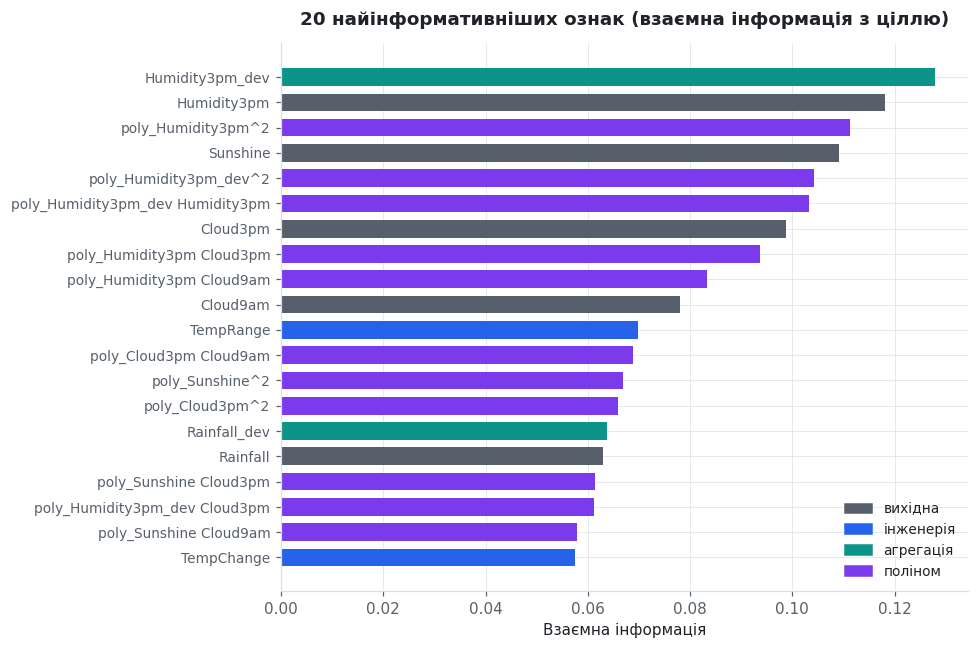

Серед 20 найінформативніших ознак створених нами: 15


In [57]:
# --- Взаємна інформація: які ознаки найінформативніші ---
mi_idx2 = X_train_fe.sample(min(20000, len(X_train_fe)), random_state=RANDOM_STATE).index

mi_all = pd.Series(
    mutual_info_classif(X_train_fe.loc[mi_idx2],
                        pd.Series(y_train, index=X_train_fe.index).loc[mi_idx2],
                        random_state=RANDOM_STATE),
    index=X_train_fe.columns,
).sort_values(ascending=False)

# Позначаємо походження кожної ознаки
def feature_origin(name):
    """Повертає тип ознаки – потрібно, щоб розфарбувати стовпчики на графіку
    і побачити, скільки серед найкорисніших ознак створено нами."""
    if name in ENGINEERED:
        return "інженерія"
    if name in DEV_FEATURES:
        return "агрегація"
    if name in POLY_FEATURES:
        return "поліном"
    return "вихідна"

top20 = mi_all.head(20).iloc[::-1]
origins = [feature_origin(n) for n in top20.index]
origin_colors = {"вихідна": MUTED, "інженерія": PALETTE[0],
                 "агрегація": PALETTE[2], "поліном": PALETTE[3]}

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(range(len(top20)), top20.values,
        color=[origin_colors[o] for o in origins], height=.7)
ax.set_yticks(range(len(top20)))
ax.set_yticklabels(top20.index, fontsize=9)

handles = [plt.Rectangle((0, 0), 1, 1, color=origin_colors[k]) for k in origin_colors]
ax.legend(handles, list(origin_colors), loc="lower right", fontsize=9)
style_axes(ax, title="20 найінформативніших ознак (взаємна інформація з ціллю)",
           xlabel="Взаємна інформація", ylabel="")
plt.tight_layout()
plt.show()

n_new_in_top = sum(1 for o in origins if o != "вихідна")
print(f"Серед 20 найінформативніших ознак створених нами: {n_new_in_top}")


In [58]:
# --- Чи покращила інженерія ознак якість моделі? ---
fe_compare = [
    evaluate_model(X_train, y_train, X_valid, y_valid, "Базовий набір ознак"),
    evaluate_model(X_train_fe, y_train, X_valid_fe, y_valid, "Базовий + інженерія ознак"),
]
fe_df = pd.DataFrame(fe_compare)
display(fe_df)

d_pr = fe_df.iloc[1]["PR-AUC"] - fe_df.iloc[0]["PR-AUC"]
d_f1 = fe_df.iloc[1]["F1"] - fe_df.iloc[0]["F1"]
print(f"Приріст PR-AUC від інженерії ознак: {d_pr:+.4f}")
print(f"Приріст F1:                        {d_f1:+.4f}")
print(f"Кількість ознак: {X_train.shape[1]} -> {X_train_fe.shape[1]} "
      f"(+{X_train_fe.shape[1] - X_train.shape[1]})")


,Варіант,Рядків у навчанні,PR-AUC,ROC-AUC,F1,Recall,Precision,"Час навчання, с"
0,Базовий набір ознак,116219,0.7445,0.8798,0.6400,0.5618,0.7434,9.8
1,Базовий + інженерія ознак,116219,0.7471,0.8816,0.6437,0.5714,0.7370,12.3


Приріст PR-AUC від інженерії ознак: +0.0026
Приріст F1:                        +0.0037
Кількість ознак: 74 -> 106 (+32)


---
# Розділ 5. Збереження артефактів і висновки

### Комірка 5.1 – збереження підготовлених даних

Зберігаємо оброблені вибірки та навчені перетворювачі, щоб використати їх у
лабораторній роботі №2 без повторного виконання всього конвеєра.

In [59]:
# --- Збереження артефактів для наступних лабораторних робіт ---
import joblib

OUT_DIR = Path("lab1_output")
OUT_DIR.mkdir(exist_ok=True)

# Підготовлені матриці ознак
# Parquet компактніший і зберігає типи даних; якщо бібліотеки немає – пишемо CSV.
try:
    X_train_fe.to_parquet(OUT_DIR / "X_train.parquet")
    X_valid_fe.to_parquet(OUT_DIR / "X_valid.parquet")
    X_test_fe.to_parquet(OUT_DIR / "X_test.parquet")
    print("Матриці ознак збережено у форматі Parquet")
except ImportError:
    for name, obj in [("X_train", X_train_fe), ("X_valid", X_valid_fe), ("X_test", X_test_fe)]:
        obj.to_csv(OUT_DIR / f"{name}.csv.gz", index=False, compression="gzip")
    print("Бібліотеки pyarrow немає – матриці збережено у стиснутому CSV (.csv.gz)")
np.save(OUT_DIR / "y_train.npy", y_train)
np.save(OUT_DIR / "y_valid.npy", y_valid)
np.save(OUT_DIR / "y_test.npy", y_test)

# Навчені перетворювачі – потрібні, щоб обробити нові дані так само
joblib.dump({
    "imputer": imputer_final,
    "power_transformer": power_final,
    "onehot_encoder": ohe,
    "ordinal_encoder": ord_enc,
    "target_encoder_mapping": te.mapping_,
    "target_encoder_global_mean": te.global_mean_,
    "frequency_map": freq_map,
    "station_stats": station_stats,
    "poly": poly,
    "poly_base": poly_base,
    "feature_names": X_train_fe.columns.tolist(),
    "num_features": NUM_FEATURES,
    "cat_features": CAT_FEATURES,
    "random_state": RANDOM_STATE,
}, OUT_DIR / "preprocessing.joblib")

# Таблиці результатів для звіту
imp_results.to_csv(OUT_DIR / "results_imputation.csv", index=False)
aug_results.to_csv(OUT_DIR / "results_augmentation.csv", index=False)
norm_tests.to_csv(OUT_DIR / "results_normality.csv", index=False)
vif_tbl.to_csv(OUT_DIR / "results_vif.csv", index=False)

print(f"Артефакти збережено в теку {OUT_DIR.resolve()}\n")
for f in sorted(OUT_DIR.iterdir()):
    print(f"  {f.name:<32} {f.stat().st_size / 1024:>9,.1f} КБ".replace(",", " "))


Матриці ознак збережено у форматі Parquet
Артефакти збережено в теку /content/lab1_output

  X_test.parquet                     1 749.4 КБ
  X_train.parquet                   17 492.8 КБ
  X_valid.parquet                    3 297.1 КБ
  preprocessing.joblib                 453.4 КБ
  results_augmentation.csv               0.4 КБ
  results_imputation.csv                 0.3 КБ
  results_normality.csv                  1.2 КБ
  results_vif.csv                        0.7 КБ
  y_test.npy                            66.3 КБ
  y_train.npy                          908.1 КБ
  y_valid.npy                          136.9 КБ


### Комірка 5.2 – зведена таблиця результатів

In [60]:
# --- Зведення ключових числових результатів роботи ---
summary = pd.DataFrame([
    ["Обсяг вихідних даних", f"{len(df_raw):,} × {df_raw.shape[1]}".replace(",", " ")],
    ["Ознак (числові + категоріальні)",
     f"{len(NUM_FEATURES)} + {len(CAT_FEATURES)} = {len(FEATURES)}"],
    ["Записів без мітки (вилучено)", f"{n_missing_target:,}".replace(",", " ")],
    ["Обсяг після очищення", f"{len(df):,}".replace(",", " ")],
    ["Дисбаланс класів", f"{share_yes:.2f} % / {share_no:.2f} % (1 : {n_no / n_yes:.2f})"],
    ["Рядків із пропусками", f"{rows_any_na:.1f} %"],
    ["Макс. частка пропусків", f"{miss.iloc[0]['Частка, %']:.2f} % ({miss.iloc[0]['Ознака']})"],
    ["Станцій без даних Sunshine",
     f"{(by_station['Sunshine'] > .99).sum()} із {df['Location'].nunique()}"],
    ["Максимальний VIF", f"{vif_tbl['VIF'].max():.1f} ({vif_tbl.iloc[0]['Ознака']})"],
    ["Найсильніша кореляція",
     f"{pairs.iloc[0]['Ознака 1']} <-> {pairs.iloc[0]['Ознака 2']}: r = {pairs.iloc[0]['Пірсон']:.3f}"],
    ["Максимальна асиметрія",
     f"{desc['skew'].abs().max():.2f} ({desc['skew'].abs().idxmax()})"],
    ["Ознак із нормальним розподілом", f"{n_normal} із {len(NUM_FEATURES)}"],
    ["Найкращий метод імпутації", f"{best} (NRMSE = {imp_results['NRMSE'].min():.4f})"],
    ["Ознак після інженерії", f"{X_train.shape[1]} -> {X_train_fe.shape[1]}"],
    ["PR-AUC базової моделі", f"{fe_df.iloc[0]['PR-AUC']:.4f}"],
    ["PR-AUC після інженерії ознак", f"{fe_df.iloc[1]['PR-AUC']:.4f}"],
], columns=["Показник", "Значення"])

display(summary)


,Показник,Значення
0,Обсяг вихідних даних,145 460 × 23
1,Ознак (числові + категоріальні),16 + 5 = 21
2,Записів без мітки (вилучено),3 267
3,Обсяг після очищення,142 193
4,Дисбаланс класів,22.42 % / 77.58 % (1 : 3.46)
5,Рядків із пропусками,61.2 %
6,Макс. частка пропусків,48.01 % (Sunshine)
7,Станцій без даних Sunshine,19 із 49
8,Максимальний VIF,56.4 (Temp3pm)
9,Найсильніша кореляція,MaxTemp <-> Temp3pm: r = 0.985
